**1. Импорт таблицы**

In [1]:
# %pip install matplotlib

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = BASE / "data" / "samples"

In [10]:
df = pd.read_csv(DATA / "data_ai_assistant.csv", sep=';', low_memory=False)
df.head()

,request_id,instruction,intent,category,tags,response,property_type,property_id,has_typos,needs_escalation,...,source_label_method,additional_labels_method,annotation_status,weak_label_confidence,noise_type,scenario_group_id,policy_context,is_synthetic,property_assignment_method,category_ru
0,bitext_00001,"Чёрт возьми, не нахожу выставленные счета, пом...",invoices,BILLING,BCEIQWZ,Счета и чеки обычно доступны в личном кабинете...,hotel,NaN,1,0,...,source_intent,weak_rules_without_property_policies,requires_manual_review,0.35,missing_letter,bitext__invoices__29,unspecified,1,source_hospitality_hotel_only,счета
1,bitext_00002,"Не нахожу выставленные счета, помогите. Где мн...",invoices,BILLING,BCIPQZ,Счета и чеки обычно доступны в личном кабинете...,hotel,NaN,1,0,...,source_intent,weak_rules_without_property_policies,requires_manual_review,0.35,transposed_letters,bitext__invoices__29,unspecified,1,source_hospitality_hotel_only,счета
2,bitext_00003,Как скачать счета из личноо кабинета? Объяснит...,invoices,BILLING,BCILPQZ,Счета и чеки обычно доступны в личном кабинете...,hotel,NaN,1,0,...,source_intent,weak_rules_without_property_policies,requires_manual_review,0.35,missing_letter,bitext__invoices__44,unspecified,1,source_hospitality_hotel_only,счета
3,bitext_00004,"Да что же это таке, подскажите, как получить к...",invoices,BILLING,BCIPWZ,Счета и чеки обычно доступны в личном кабинете...,hotel,NaN,1,0,...,source_intent,weak_rules_without_property_policies,requires_manual_review,0.35,missing_letter,bitext__invoices__67,unspecified,1,source_hospitality_hotel_only,счета
4,bitext_00005,"Не нахожу выставленные счета, помогите. Что дл...",invoices,BILLING,BCILM,Счета и чеки обычно доступны в личном кабинете...,hotel,NaN,0,0,...,source_intent,weak_rules_without_property_policies,requires_manual_review,0.35,none,bitext__invoices__29,unspecified,1,source_hospitality_hotel_only,счета


**2. Основная информация**

*Описание датасета:*
- Датасет: data_ai_assistant.csv
- Тип: гибридный
- Количество объектов/строк: 35000
- Количество признаков/столбцов: 27

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 35000 entries, 0 to 34999
Data columns (total 27 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   request_id                  35000 non-null  str    
 1   instruction                 35000 non-null  str    
 2   intent                      35000 non-null  str    
 3   category                    35000 non-null  str    
 4   tags                        35000 non-null  str    
 5   response                    35000 non-null  str    
 6   property_type               35000 non-null  str    
 7   property_id                 0 non-null      float64
 8   has_typos                   35000 non-null  int64  
 9   needs_escalation            35000 non-null  int64  
 10  priority                    35000 non-null  str    
 11  language                    35000 non-null  str    
 12  source_dataset              35000 non-null  str    
 13  source_row_id               25000 non-null

*Описание полей:*
- **request_id** (`str`) — уникальный id записи вида bitext_N, где N = 00001..35000
- **instruction** (`str`) — текст обращения гостя на русском (после перевода)
- **intent** (`str`) — тип обращения, класс намерения; целевая метка классификатора
- **category** (`str`) — укрупнённая категория, группа интентов (грубее, чем intent)
- **tags** (`str`) — теги записи
- **response** (`str`) — ответ бота на это обращение (эталонный или сгенерированный)
- **property_type** (`str`) — тип объекта: apartment / hotel / guesthouse
- **has_typos** (`int64`) — бинарный флаг: есть ли в тексте опечатки (0/1)
- **needs_escalation** (`int64`) — целевая метка: 0 — бот отвечает сам, 1 — требуется человек
- **priority** (`str`) — приоритет обращения 
- **language** (`str`) — язык обращения (ожидается `ru` во всех строках)
- **source_dataset** (`str`) — исходный датасет, откуда взята строка
- **source_row_id** (`float64`) — id строки в исходном датасете; заполнено 25 000 из 35 000, `float64` — некорректный тип для идентификатора
- **original_instruction_en** (`str`) — исходный текст на английском до перевода; заполнено 25 000
- **original_response_en** (`str`) — исходный ответ на английском до перевода; заполнено 25 000
- **is_synthetic** (`int64`) — бинарный флаг: 1 — строка синтетическая, 0 — из реального источника

**Вывод:** Практически по всем столбцам полное заполнение для всех 35000 строк. 
Исключения: столбцы source_row_id, original_instruction_en, original_response_en, где заполнены 25000 строк. Это наши дополнительно добавленные 10000 строк сразу на русском языке.

**3. Анализ признаков**

**Текстовые признаки**

In [12]:
str_values = ['request_id', 'instruction', 'response']
for column in str_values:
    is_not_empty = df[column].astype(str).str.strip() != ''
    print(f"Количество корректных (заполненных) строк '{column}': {is_not_empty.sum()} из {df.shape[0]}")

Количество корректных (заполненных) строк 'request_id': 35000 из 35000
Количество корректных (заполненных) строк 'instruction': 35000 из 35000
Количество корректных (заполненных) строк 'response': 35000 из 35000


*Вывод:* Текстовые поля 'request_id', 'instruction', 'response' не содержат пропусков или пустых значений.
<br>
<br>
<br>

**Категориальные признаки**

- *Тип недвижимости 'property_type'*

Возможные значения:

In [13]:
df['property_type'].unique()

<StringArray>
['hotel', 'apartment', 'guesthouse']
Length: 3, dtype: str

Сумма по группам:

In [14]:
print("сумма групп:", df.groupby("property_type").size().sum())
vc = df["property_type"].value_counts()
pd.DataFrame({
    "кол-во, шт": vc,
    "доля, %": (vc / vc.sum() * 100).round(1),
})

сумма групп: 35000


,"кол-во, шт","доля, %"
property_type,,
hotel,28430,81.2
guesthouse,3484,10.0
apartment,3086,8.8


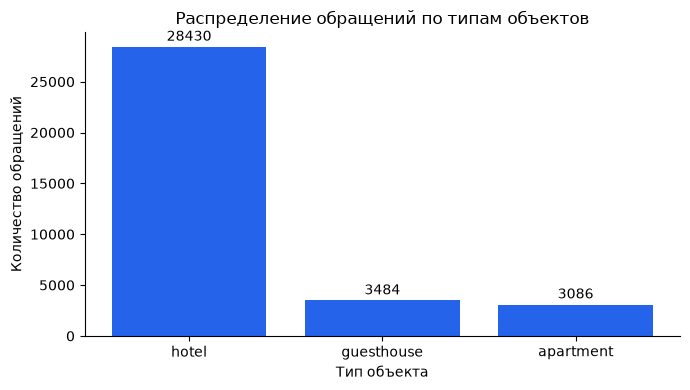

In [15]:
counts = df["property_type"].value_counts()   # уже отсортировано по убыванию

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(counts.index, counts.values, color="#2563EB")
ax.bar_label(bars, fmt="%d", padding=2)        # числа над столбиками

ax.set_title("Распределение обращений по типам объектов")
ax.set_xlabel("Тип объекта")
ax.set_ylabel("Количество обращений")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

Доля исходных обращений для разных типов недвижимости:

In [16]:
g = df.groupby("property_type")["original_instruction_en"].agg(
    total="size",
    is_origin="count",
)
g["is_added"] = g["total"] - g["is_origin"]
print(g)

               total  is_origin  is_added
property_type                            
apartment       3086          0      3086
guesthouse      3484          0      3484
hotel          28430      25000      3430


*Вывод:* Имеется три типа недвижимости 'hotel', 'apartment', 'guesthouse'. Мы видим,  что 81% обращений относятся к отелям, что не отражает реальную структуру рынка краткосрочной аренды, а является следствием формирования датасета, который изначально формировался под отели и куда мы искусственно добавили дополнительные обращения для всех 3 типов недвижимости. Способ устранения дисбаланса рассмотрим на этапе обучения.
<br>
<br>

- *Категории 'category' и интенты 'intent'*

Все возможные значения категорий:

In [17]:
df['category'].unique()

<StringArray>
[          'BILLING', 'CANCELLATION_FEES',          'CHECK_IN',
         'CHECK_OUT',           'CONTACT',             'EVENT',
          'FEEDBACK',             'HOTEL',           'LUGGAGE',
              'MENU',             'NIGHT',     'PARKING_SPACE',
              'PETS',            'POINTS',            'REFUND',
   'SHUTTLE_SERVICE',    'GUEST_SERVICES',           'BOOKING',
       'MAINTENANCE',         'COMPLAINT',         'DEPARTURE',
       'HOUSE_RULES',           'ARRIVAL',        'FACILITIES',
      'HOUSEKEEPING',            'ACCESS',            'SAFETY',
       'LOCAL_GUIDE',     'ACCESSIBILITY']
Length: 29, dtype: str

<br>
Все возможные значения интентов:

In [18]:
df['intent'].unique()

<StringArray>
[                'invoices',        'cancellation_fees',
                 'check_in',                'check_out',
         'customer_service',              'human_agent',
               'host_event',           'file_complaint',
             'leave_review',               'book_hotel',
 'cancel_hotel_reservation', 'change_hotel_reservation',
   'check_hotel_facilities',       'check_hotel_offers',
       'check_hotel_prices',  'check_hotel_reservation',
             'search_hotel',            'store_luggage',
               'check_menu',                'add_night',
       'book_parking_space',               'bring_pets',
            'redeem_points',               'get_refund',
          'shuttle_service',            'lost_property',
             'extra_guests',             'wifi_problem',
          'noise_complaint',             'power_outage',
   'late_check_out_request',           'pest_complaint',
            'visitor_rules', 'air_conditioning_problem',
   'early_check_i

<br>
Интенты, сгруппированные по категориям, в порядке убывания:

In [19]:
categorized_total = 0
for cat in df["category"].value_counts().index:
    g = df[df["category"] == cat]
    print(f"\n{cat}  ({len(g)}, {len(g)/len(df):.2%})")
    for intent, n in g["intent"].value_counts().items():
        categorized_total += n
        print(f"   {intent:26s} {n:5d}")
print(f"\nВсего строк с корректными интентами/категориями: {categorized_total}")


HOTEL  (8969, 25.63%)
   check_hotel_facilities      1136
   check_hotel_offers          1126
   check_hotel_prices          1126
   change_hotel_reservation    1122
   cancel_hotel_reservation    1120
   search_hotel                1120
   book_hotel                  1110
   check_hotel_reservation     1109

CONTACT  (2259, 6.45%)
   customer_service            1131
   human_agent                 1128

FEEDBACK  (2214, 6.33%)
   file_complaint              1109
   leave_review                1105

PARKING_SPACE  (1509, 4.31%)
   book_parking_space          1114
   parking_problem              198
   parking_information          197

BILLING  (1324, 3.78%)
   invoices                    1125
   billing_dispute              199

MAINTENANCE  (1283, 3.67%)
   access_problem               204
   air_conditioning_problem     197
   appliance_problem            194
   wifi_problem                 193
   water_problem                191
   heating_problem              176
   power_outage   

In [20]:
chk = df.groupby("intent", dropna=False)["category"].agg(
    строк="size",
    категорий=lambda s: s.dropna().astype(str).str.strip().replace("", pd.NA).dropna().nunique(),
    какие=lambda s: ", ".join(sorted(s.dropna().astype(str).str.strip().unique())),
)
chk = chk.sort_values("категорий", ascending=False)

print(chk)
print()
print("интентов без категории      :", (chk["категорий"] == 0).sum())
print("интентов с >1 категорией    :", (chk["категорий"] > 1).sum())
print("строк с пустой категорией   :",
      df["category"].isna().sum() + (df["category"].astype(str).str.strip() == "").sum())

                        строк  категорий        какие
intent                                               
access_problem            204          1  MAINTENANCE
pet_issue                 182          1    COMPLAINT
kitchen_usage             188          1   FACILITIES
late_check_out_request    199          1    DEPARTURE
laundry_information       196          1   FACILITIES
...                       ...        ...          ...
early_check_in_request    173          1      ARRIVAL
extra_guests              201          1      BOOKING
file_complaint           1109          1     FEEDBACK
get_refund               1113          1       REFUND
wifi_problem              193          1  MAINTENANCE

[63 rows x 3 columns]

интентов без категории      : 0
интентов с >1 категорией    : 0
строк с пустой категорией   : 0


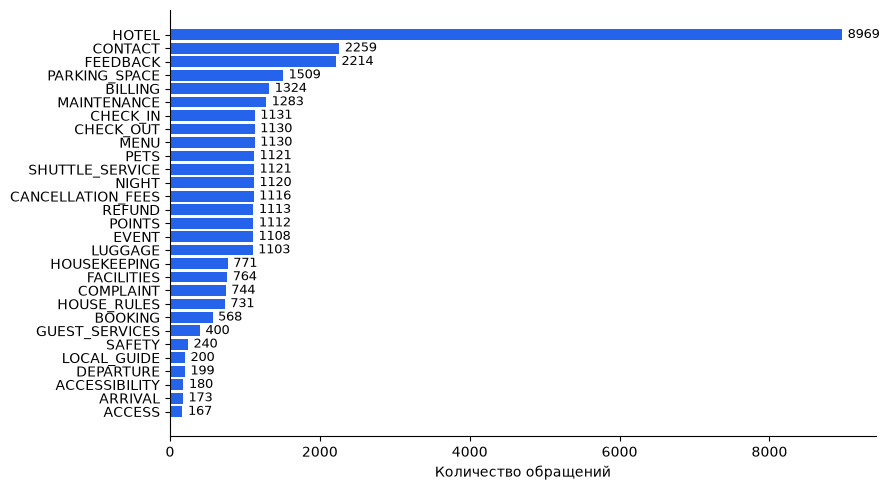

In [21]:
cat = df["category"].value_counts()
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(cat.index[::-1], cat.values[::-1], color="#2563EB")

ax.bar_label(bars, fmt="%d", padding=4, fontsize=9)
ax.set_xlabel("Количество обращений")
ax.set_ylabel("")
ax.tick_params(labelsize=10)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

Самые популярные категории обращений по типам проживания:

In [22]:
for prop, sub in df.groupby("property_type", dropna=False):
    vc = sub["category"].value_counts(normalize=True).mul(100)
    t = (vc.head(3).to_frame("доля, %").assign(шт=sub["category"].value_counts().head(3)))
    print(f"\n{prop}  ({len(sub)} строк)")
    print(t.round(1).to_string())
    print()


apartment  (3086 строк)
             доля, %   шт
category                 
MAINTENANCE     13.5  416
HOTEL           10.4  321
FACILITIES       9.1  282


guesthouse  (3484 строк)
             доля, %   шт
category                 
MAINTENANCE     12.5  436
HOTEL            9.1  316
FACILITIES       8.0  277


hotel  (28430 строк)
          доля, %    шт
category               
HOTEL        29.3  8332
CONTACT       7.3  2071
FEEDBACK      7.3  2064



Доля категории HOTEL для всех обращений:

In [23]:
n = (df["category"].astype(str).str.strip().str.lower() == "hotel").sum()
print(f"{n:,} из {len(df):,} = {n / len(df):.1%}")

8,969 из 35,000 = 25.6%


*Вывод:* После проверки столбцов 'category', 'intent' мы видим, что данные корректные. Нет интентов без категории и нет пустых категорий, значения присутствуют в каждой строке. Можно заметить, что обращения с категорией Hotel самые многочисленные в целом (25.6%) и в категории отелей (29%). Лидерство категории объясняется двумя причинами: составом выборки (81% записей — отели) и устойчивой связью темы с типом объекта.
<br>
<br>

- *Приоритет обращения 'priority'*

Возможные значения:

In [24]:
df['priority'].unique()

<StringArray>
['low', 'medium', 'high', 'critical']
Length: 4, dtype: str

In [25]:
df["priority"].value_counts(dropna=False)

priority
low         23435
medium       9313
high         1965
critical      287
Name: count, dtype: int64

Категории с самой большой долей обращений с приоритетом Critical:

In [26]:
raw = pd.crosstab(df["category"], df["priority"]).reindex(columns=["critical"], fill_value=0)
keep = raw["critical"] > 0

c = pd.crosstab(df["category"], df["priority"], normalize="index").mul(100).round(1)
print(c.loc[keep, ["critical"]].sort_values("critical", ascending=False))

priority     critical
category             
SAFETY           96.2
MAINTENANCE       4.4


Доля обращений с приоритетом critical среди интентов по убыванию:

In [27]:
t = pd.crosstab(df["intent"], df["priority"])
t["всего"] = t.sum(axis=1)
t["critical, %"] = (t["critical"] / t["всего"] * 100).round(1)
print(
    t[t["critical"] > 0]  
    .sort_values("critical, %", ascending=False)[["critical", "всего", "critical, %"]]
    .to_string()
)

priority           critical  всего  critical, %
intent                                         
medical_emergency       107    107        100.0
safety_incident         124    133         93.2
power_outage             56    128         43.8


Распределение приоритетов среди категорий:

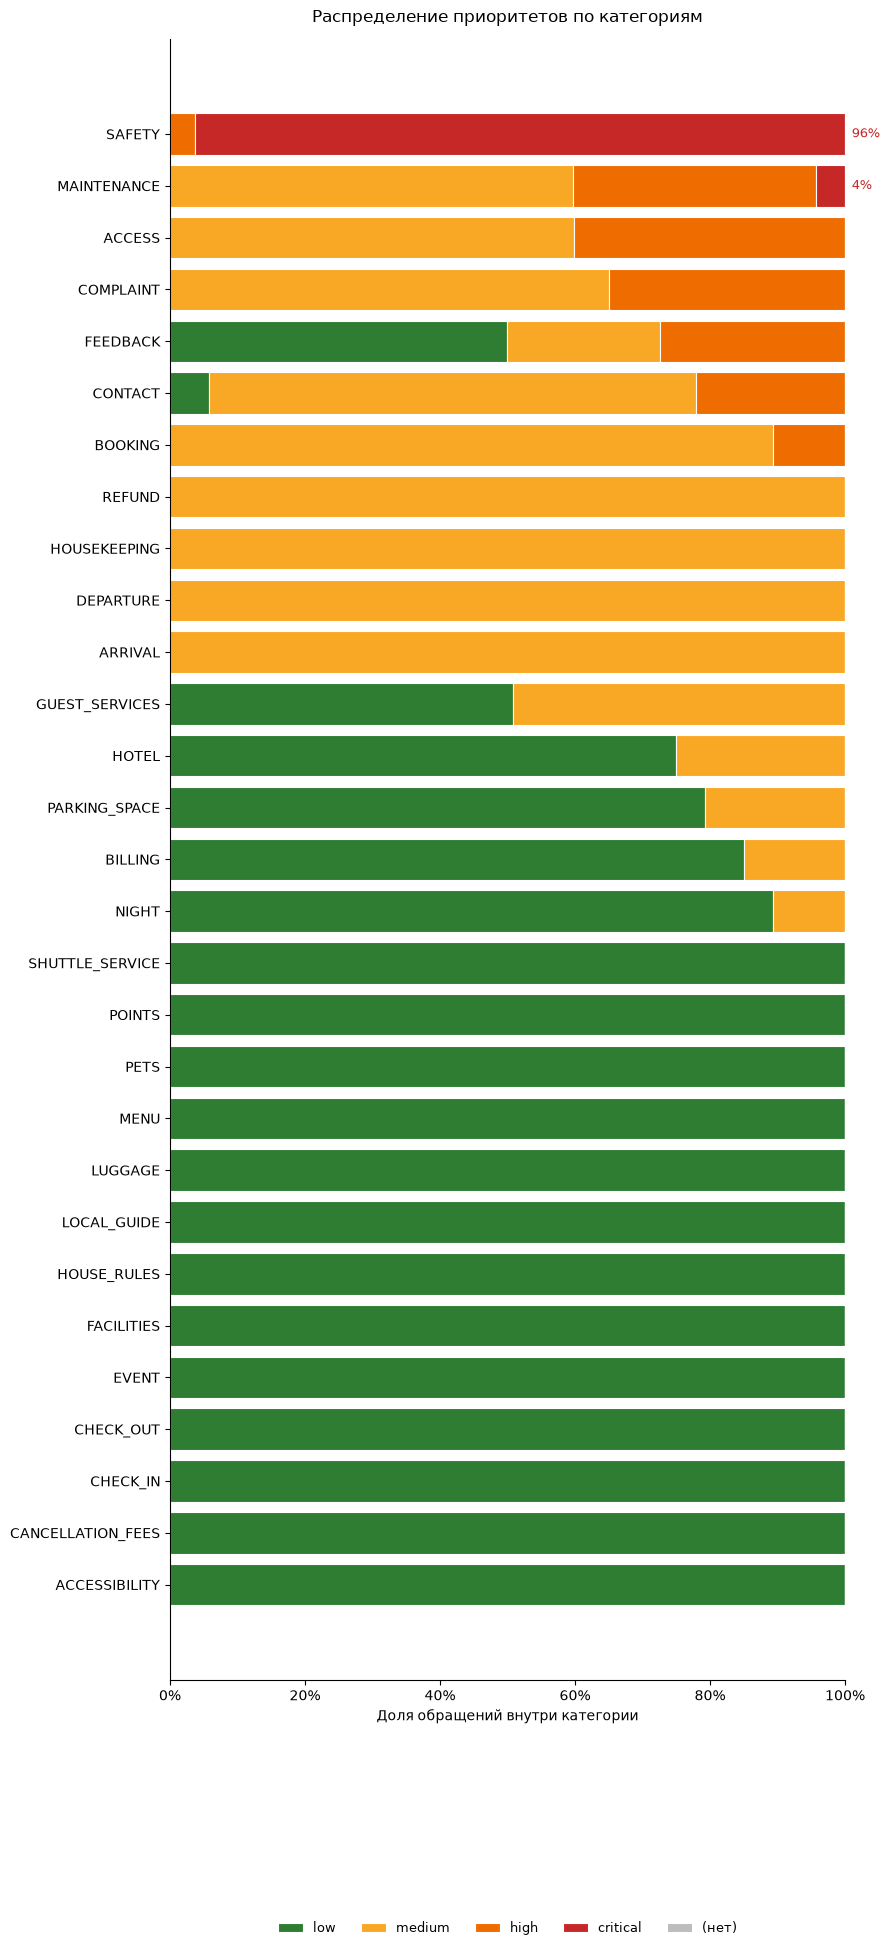

In [28]:
order  = ["low", "medium", "high", "critical", "(нет)"]
colors = {"low":      "#2E7D32",
          "medium":   "#F9A825",
          "high":     "#EF6C00",
          "critical": "#C62828",
          "(нет)":    "#BDBDBD"}

sub = df.copy()
sub["priority"] = sub["priority"].fillna("(нет)")

share = pd.crosstab(sub["category"], sub["priority"]).reindex(columns=order, fill_value=0)
share = share.div(share.sum(axis=1), axis=0)

share = share.sort_values(
    ["critical", "high", "medium", "low", "(нет)"],
    ascending=[True, True, True, True, False],
)

fig, ax = plt.subplots(figsize=(9, 0.6 * len(share) + 2))
left = np.zeros(len(share))

for p in order:
    ax.barh(share.index, share[p], left=left, color=colors[p],
            label=p, edgecolor="white", linewidth=0.8)
    left += share[p].values

for y, v in enumerate(share["critical"]):
    if v > 0:
        ax.text(1.01, y, f"{v:.0%}", va="center", fontsize=9, color=colors["critical"])

ax.set_xlim(0, 1)
ax.set_xlabel("Доля обращений внутри категории")
ax.set_title("Распределение приоритетов по категориям", pad=12)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.tick_params(labelsize=10)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.14),
          frameon=False, fontsize=9)

plt.tight_layout()
plt.show()

*Вывод:* Столбец 'priority' содержит 4 значения приоритетов обращений от critical к low. Основная масса обращений имеет самый низкий приоритет. Так же определены категории, где высокая доля обращений с самым высоким приоритетом, это SAFETY (Безопасность) и MAINTENANCE (Обслуживание). В интентах категории SAFETY доля critical обращений стремится к 100%.
На графике можно увидеть распределение приоритетов внутри категорий. Мы видим, что вопросы безопасности, обслуживания, доступа, жалобы имеют высокий приоритет, в то время как вопросы, касающиеся стандартных тем типа заселения, багажа, а так же дополнительные услуги типа меню, размещения с питомцами имеют низкий приоритет.
<br>
<br>

**Бинарные признаки**

- *Наличие опечаток 'has_typos'*
- *Целевая переменная: Решение об эскалации 'needs_escalation'*

In [29]:
bins = ["has_typos", "needs_escalation"]

for c in bins:
    vc = df[c].value_counts(dropna=False)
    print(f"{c:18s} {vc.to_dict()}   доля 1: {df[c].mean():.1%}")

has_typos          {0: 21836, 1: 13164}   доля 1: 37.6%
needs_escalation   {1: 18446, 0: 16554}   доля 1: 52.7%


*Вывод:* Столбцы 'has_typos' и 'needs_escalation' принимают значения 0 и 1. Пустых значений нет, так же нет некорректных значений. Баланс нормальный. По балансу можно сделать вывод, что доля эскалаций больше половины, а значит продукт смог бы сэнонмить владельцу всего половину работы.

**Выводы:**

**1. Данные.** 35 000 записей: 25 000 переведены с английского, 10 000 изначально на русском. Пропусков и пустых значений в содержательных колонках нет, дубликатов не обнаружено. Происхождение каждой записи зафиксировано, что позволяет считать метрики раздельно.

**2. Типы объектов.** 81% записей — отели, по 9–10% квартиры и гостевые дома. Это следствие формирования датасета, а не структуры рынка краткосрочной аренды. Отсюда два обязательных решения: стратификация train/test по типу объекта и раздельные метрики по каждому типу.

**3. Метки корректны.** У каждого интента ровно одна категория, пустых значений нет. Категория `HOTEL` лидирует по двум причинам: отелей численно больше, и внутри отелей эта тема тоже доминирует — то есть её популярность не объясняется только размером группы.

**4. Приоритеты осмысленны.** Четыре уровня от `low` до `critical`, шкала используется полностью. `critical` сосредоточен в категориях `SAFETY` и `MAINTENANCE`, спокойные темы (заселение, багаж, доп. услуги) высокого приоритета не получают — это соответствует политике.

**5. Эскалация — главная проблема продукта.** Метка сбалансирована (52/48), но 52% эскалаций означают, что консьерж закрывает меньше половины обращений. Целевой уровень для такого продукта — 15–25%. Нужна ревизия разметки: вероятно, часть обращений с ответом в базе знаний помечена как требующая человека.

## Часть 2 Исследовательский анализ эскалаций

### Подготовка данных и контроль целевых меток


На первом этапе необходимо проверить, что признаки, используемые для анализа эскалации и приоритетов, имеют корректные типы и допустимые значения.

В датасете используются две целевые переменные: needs_escalation — бинарный признак необходимости передачи обращения сотруднику, и priority — порядковая категориальная переменная, характеризующая срочность реагирования.

Для сохранения воспроизводимости создадим отдельную копию исходного датасета.

In [30]:
import seaborn as sns

In [31]:
RANDOM_STATE = 42

PRIORITY_ORDER = ["low","medium","high","critical"]
sns.set_theme(style="whitegrid")
eda = df.copy(deep=True)

required_columns = {"request_id","instruction","intent","category","property_type","priority","needs_escalation","has_typos","scenario_group_id","annotation_status"}
missing = required_columns - set(eda.columns)
assert not missing, f"Отсутствующие колонки: {missing}"
assert eda["request_id"].is_unique

for col in ["needs_escalation", "has_typos"]:
    eda[col] = pd.to_numeric(eda[col],errors="raise").astype("int8")

eda["priority"] = (eda["priority"].astype("string").str.strip().str.lower())

assert eda["needs_escalation"].isin([0, 1]).all()
assert eda["has_typos"].isin([0, 1]).all()
assert eda["priority"].isin(PRIORITY_ORDER).all()

eda["word_count"] = (eda["instruction"].fillna("").str.findall(r"(?u)\b\w+\b").str.len())

print("Количество обращений:", len(eda))
print("Количество намерений:", eda["intent"].nunique())
print("Количество сценарных групп:", eda["scenario_group_id"].nunique())

print("\nКонтроль пропусков:")
display(eda[["intent", "priority", "needs_escalation"]].isna().sum())

Количество обращений: 35000
Количество намерений: 63
Количество сценарных групп: 902

Контроль пропусков:


intent              0
priority            0
needs_escalation    0
dtype: int64

Проверка подтвердила наличие 35 000 обращений, распределённых между 63 намерениями и 902 сценарными группами. Признаки эскалации и наличия опечаток имеют допустимые бинарные значения, а переменная приоритета принимает четыре значения: low, medium, high, critical.

Пропуски в рассматриваемых целевых полях отсутствуют.

Таким образом, данные технически согласованы и допускают применение методов описательной статистики и анализа категориальных зависимостей.

### Зависимость эскалации от намерения пользователя

Одной из основных гипотез проекта является предположение о том, что необходимость эскалации связана с характером пользовательского запроса.

В зависимости от намерения AI-консьерж может предоставлять информационный ответ, выполнять разрешённое действие или передавать обращение сотруднику. Поэтому необходимо установить, как распределяется доля эскалаций между различными intent.

Для каждого намерения рассчитаем количество обращений, число эскалаций и относительную долю needs_escalation = 1.

Дополнительно используем 95%-е интервалы Уилсона. Они позволяют учитывать различия в объёме наблюдений и корректнее отражают неопределённость пропорций, особенно когда наблюдаемая доля близка к нулю или единице.

In [32]:
intent_stats = (eda.groupby("intent").agg(n=("request_id", "size"),n_escalations=("needs_escalation", "sum")))
intent_stats["rate"] = (intent_stats["n_escalations"]/ intent_stats["n"])
z = 1.959963984540054 #интервал Уилсона

n = intent_stats["n"].to_numpy(dtype=float)
p = intent_stats["rate"].to_numpy(dtype=float)

denominator = 1 + z**2 / n
center = (p + z**2 / (2 * n)) / denominator
half_width = (z / denominator* np.sqrt(p * (1 - p) / n+ z**2 / (4 * n**2)))
intent_stats["ci_lower"] = np.clip(center - half_width, 0, 1)
intent_stats["ci_upper"] = np.clip(center + half_width, 0, 1)

top_names = (eda["intent"].value_counts().head(15).index)
top = (intent_stats.loc[top_names].sort_values("rate").copy())

left_error = np.maximum(top["rate"] - top["ci_lower"],0.0).to_numpy(dtype=float)
right_error = np.maximum(top["ci_upper"] - top["rate"],0.0).to_numpy(dtype=float)

xerr = np.vstack([left_error, right_error])

assert np.isfinite(xerr).all()
assert (xerr >= 0).all()

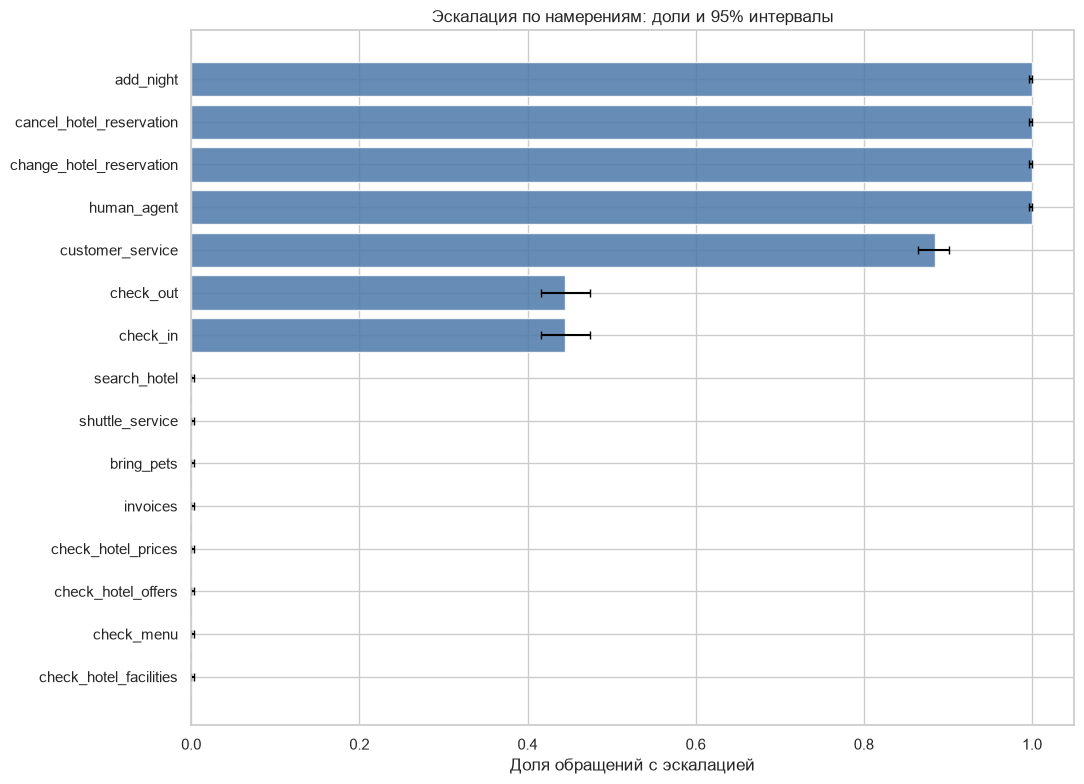

,n,n_escalations,rate,ci_lower,ci_upper
intent,,,,,
access_problem,204,204,1.0,0.9815,1.0000
cleaning_request,199,199,1.0,0.9811,1.0000
extra_guests,201,201,1.0,0.9812,1.0000
file_complaint,1109,1109,1.0,0.9965,1.0000
get_refund,1113,1113,1.0,0.9966,1.0000
...,...,...,...,...,...
local_recommendation,200,0,0.0,0.0000,0.0188
check_hotel_facilities,1136,0,0.0,0.0000,0.0034
leave_review,1105,0,0.0,0.0000,0.0035


In [33]:
fig, ax = plt.subplots(figsize=(11, 8))
y = np.arange(len(top))
ax.barh(y,top["rate"],color="#4C78A8",alpha=0.85)
ax.errorbar(x=top["rate"].to_numpy(),y=y,xerr=xerr,fmt="none",ecolor="black",capsize=3)
ax.set_yticks(y)
ax.set_yticklabels(top.index)
ax.set_xlim(0, 1.05)
ax.set_xlabel("Доля обращений с эскалацией")
ax.set_title("Эскалация по намерениям: доли и 95% интервалы")
plt.tight_layout()
plt.show()

display(intent_stats.sort_values("rate", ascending=False).round(4))

Анализируя полученный график можно заметить существенную неоднородность долей эскалации между намерениями.
Это означает, что в текущей структуре разметки необходимость эскалации в значительной степени определяется самим намерением пользователя.

Например, запросы на изменение бронирования и обращения, требующие участия оператора, имеют высокую частоту передачи сотруднику. Напротив, отдельные информационные намерения полностью представлены обращениями без эскалации.

С практической точки зрения результат показывает, что распознавание намерения может стать важным этапом определения дальнейшего маршрута обработки обращения.


### Количественная оценка зависимости меток от intent

Здесь попытаемся исследовать , какая доля целевых значений может быть восстановлена исключительно по наиболее распространённой метке внутри каждого намерения.

Данная оценка позволит установить, насколько дополнительная информация о намерении повышает согласованность предсказаний с имеющейся разметкой.


In [34]:
def majority_agreement(data, feature, target):
    table = pd.crosstab(data[feature],data[target])
    majority_count = (table.max(axis=1).sum())

    return majority_count / len(data)


results = []

for target in ["needs_escalation", "priority"]:
    global_baseline = (eda[target].value_counts(normalize=True).max())
    intent_agreement = majority_agreement(eda,"intent",target)
    results.append({
        "Target": target,
        "Global baseline": global_baseline,
        "Intent majority": intent_agreement,
        "Difference": (intent_agreement - global_baseline)
    })

agreement_df = pd.DataFrame(results)
display(agreement_df.round(4))

,Target,Global baseline,Intent majority,Difference
0,needs_escalation,0.5270,0.9516,0.4245
1,priority,0.6696,0.9494,0.2798


Предоставленные резуальтаты демонситруют существенную дополнительную информацию, содержащуюся в метке намерения.

Для эскалации переход от глобального большинства к учёту intent повышает согласованность с разметкой на 42,45 процентного пункта. А для приоритета прирост составляет 27,98 процентного пункта. Следовательно, обе целевые переменные обладают выраженной зависимостью от типа пользовательского запроса.

Это дает нам два следсвия для ML:
 - распознавание намерения может быть полезным компонентом системы маршрутизации обращений и определения срочности;
 - классификаторы эскалации и приоритета могут показывать высокую согласованность с текущими метками, используя преимущественно информацию о intent, без глубокого анализа конкретной ситуации.

### Совместный анализ эскалации и приоритета

Так как эскалация и приоритет описывают разные характеристики обращения, то здесь важно определить, насколько независимо представлены эти признаки и какие сочетания решений встречаются в корпусе.

Для этого построим таблицу сопряжённости и условное распределение эскалаций по уровням приоритета.

In [35]:
priority_esc = pd.crosstab(eda["priority"],eda["needs_escalation"]).reindex(index=PRIORITY_ORDER,columns=[0, 1],fill_value=0)
display(priority_esc)
priority_esc_pct = (priority_esc.div(priority_esc.sum(axis=1), axis=0).mul(100))

needs_escalation,0,1
priority,,
low,16554,6881
medium,0,9313
high,0,1965
critical,0,287


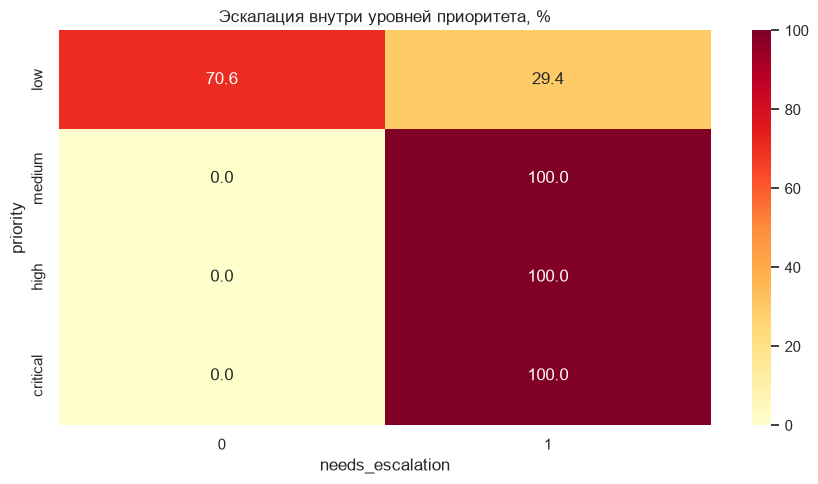

Всего обращений с эскалацией: 18446
Обращений low с эскалацией: 6881


In [36]:
plt.figure(figsize=(9, 5))
sns.heatmap(priority_esc_pct,annot=True,fmt=".1f",cmap="YlOrRd",vmin=0,vmax=100)
plt.title("Эскалация внутри уровней приоритета, %")
plt.xlabel("needs_escalation")
plt.ylabel("priority")
plt.tight_layout()
plt.show()
print("Всего обращений с эскалацией:",int(eda["needs_escalation"].sum()))
print("Обращений low с эскалацией:",int(priority_esc.loc["low", 1]))

приоритет и эскалация являются связанными, но содержательно различными целевыми переменными. При разработке ML-системы целесообразно рассматривать их как отдельные задачи, а найденную зависимость учитывать при проектировании совместной логики принятия решений.

### Статистическая связь эскалации с категориальными признаками

Для определения факторов, наиболее тесно связанных с эскалацией, необходимо сравнить силу статистической ассоциации различных категориальных признаков с целевой переменной.

Использутся коэффициент V Крамера, основанный на статистике критерия хи-квадрат.

In [37]:
from scipy.stats import chi2_contingency

In [38]:
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    if min(table.shape) < 2:
        return np.nan
    chi2 = chi2_contingency(table,correction=False).statistic
    n = table.to_numpy().sum()
    value = np.sqrt(chi2 / (n * min(table.shape[0] - 1,table.shape[1] - 1)))

    return float(value)


feature_pairs = [
    ("intent", "needs_escalation"),
    ("category", "needs_escalation"),
    ("priority", "needs_escalation"),
    ("property_type", "needs_escalation"),
    ("has_typos", "needs_escalation"),
    ("intent", "priority")
]

association_results = []
for feature_1, feature_2 in feature_pairs:
    association_results.append({"Feature 1": feature_1,"Feature 2": feature_2,"Cramers V": cramers_v(eda[feature_1],eda[feature_2])})
association_df = (pd.DataFrame(association_results).sort_values("Cramers V", ascending=False))
display(association_df.round(4))

,Feature 1,Feature 2,Cramers V
0,intent,needs_escalation,0.9316
5,intent,priority,0.8785
1,category,needs_escalation,0.7261
2,priority,needs_escalation,0.6655
3,property_type,needs_escalation,0.0304
4,has_typos,needs_escalation,0.0150


Наиболее выраженная связь эскалации наблюдается с намерением пользователя. Коэффициент V Крамера составляет 0,9316, что указывает на очень сильную ассоциацию.

Укрупнённая категория также связана с эскалацией, однако слабее, чем более детализированное намерение. Это согласуется с иерархической структурой признаков, при которой одна категория включает несколько различных сценариев обращения.

### Эскалация и тип объекта размещения: контроль неоднородности выборки

AI-консьерж проектируется как универсальная система для отелей, квартир краткосрочного проживания и гостевых домов. При этом правила обработки обращений могут существенно различаться между объектами. Для более сопоставимого исследования выделим часть корпуса, в которой представлены все три типа объектов, и оценим распределение эскалаций внутри неё.

In [39]:
eda_types = eda.loc[eda["source_dataset"] == "team_generated_ru_v2"].copy()
property_stats = (eda_types.groupby("property_type").agg(
        n=("request_id", "size"),
        n_escalations=("needs_escalation", "sum"),
        escalation_rate=("needs_escalation", "mean"),
        n_intents=("intent", "nunique")
    )
)
display(property_stats.round(4))

,n,n_escalations,escalation_rate,n_intents
property_type,,,,
apartment,3086,1756,0.5690,57
guesthouse,3484,1903,0.5462,62
hotel,3430,1906,0.5557,62


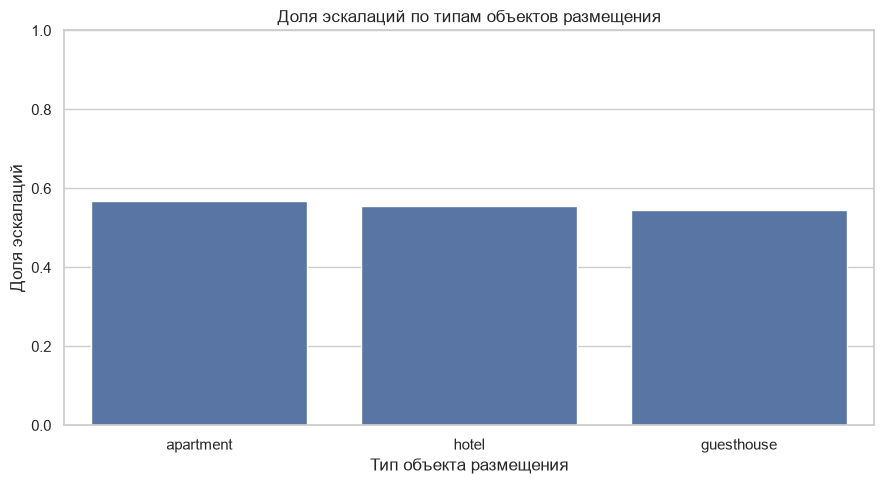

In [40]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=eda_types,x="property_type",y="needs_escalation",errorbar=None,ax=ax)
ax.set_ylim(0, 1)
ax.set_title("Доля эскалаций по типам объектов размещения")
ax.set_xlabel("Тип объекта размещения")
ax.set_ylabel("Доля эскалаций")
plt.tight_layout()
plt.show()

In [41]:
# Проверяем разнообразие решений внутри intent
intent_variability = (eda_types.groupby("intent")["needs_escalation"].nunique())
print("Интентов с несколькими значениями эскалации:",int((intent_variability > 1).sum()))
print("Интентов с постоянной меткой:",int((intent_variability == 1).sum()))

Интентов с несколькими значениями эскалации: 0
Интентов с постоянной меткой: 63


В рассматриваемой части корпуса доли эскалаций находятся в сравнительно узком диапазоне — от 54,62% до 56,90%. С одной стороны это указывает на сходство распределений решений для трёх типов объектов. Однако дополнительный анализ выявил принципиальное ограничение: у всех 63 намерений внутри этой выборки метка эскалации постоянна.

Таким образом различия долей эскалаций между типами объектов объясняются прежде всего различиями в представленности намерений. Данные не содержат достаточной вариативности для исследования того, как тип объекта изменяет решение при фиксированном намерении.

А в разработке это особенно важно для архитектуры универсального AI-консьержа.Так как решение об эскалации должно определяться не общей категорией «отель» или «квартира», а правилами конкретного объекта и обстоятельствами обращения.

## Часть 3. Углублённый анализ приоритетов

### Вариативность приоритета внутри намерений

Для автоматической приоритизации обращений необходимо установить, насколько уровень срочности зависит от типа запроса и насколько он изменяется в пределах одного намерения.

Если каждому intent соответствует фиксированный приоритет, то задача модели фактически сводится к определению намерения и последующему сопоставлению его с заранее заданным уровнем срочности.

Такая схема может быть полезна для простой маршрутизации, однако не обеспечивает полноценную оценку обстоятельств обращения.

In [42]:
priority_variability = (eda.groupby("intent")["priority"].nunique())
display(priority_variability.value_counts().sort_index().to_frame("Количество намерений"))
n_single_priority = int((priority_variability == 1).sum())
print("Интентов с одним приоритетом:",n_single_priority)

,Количество намерений
priority,
1,50
2,13


Интентов с одним приоритетом: 50


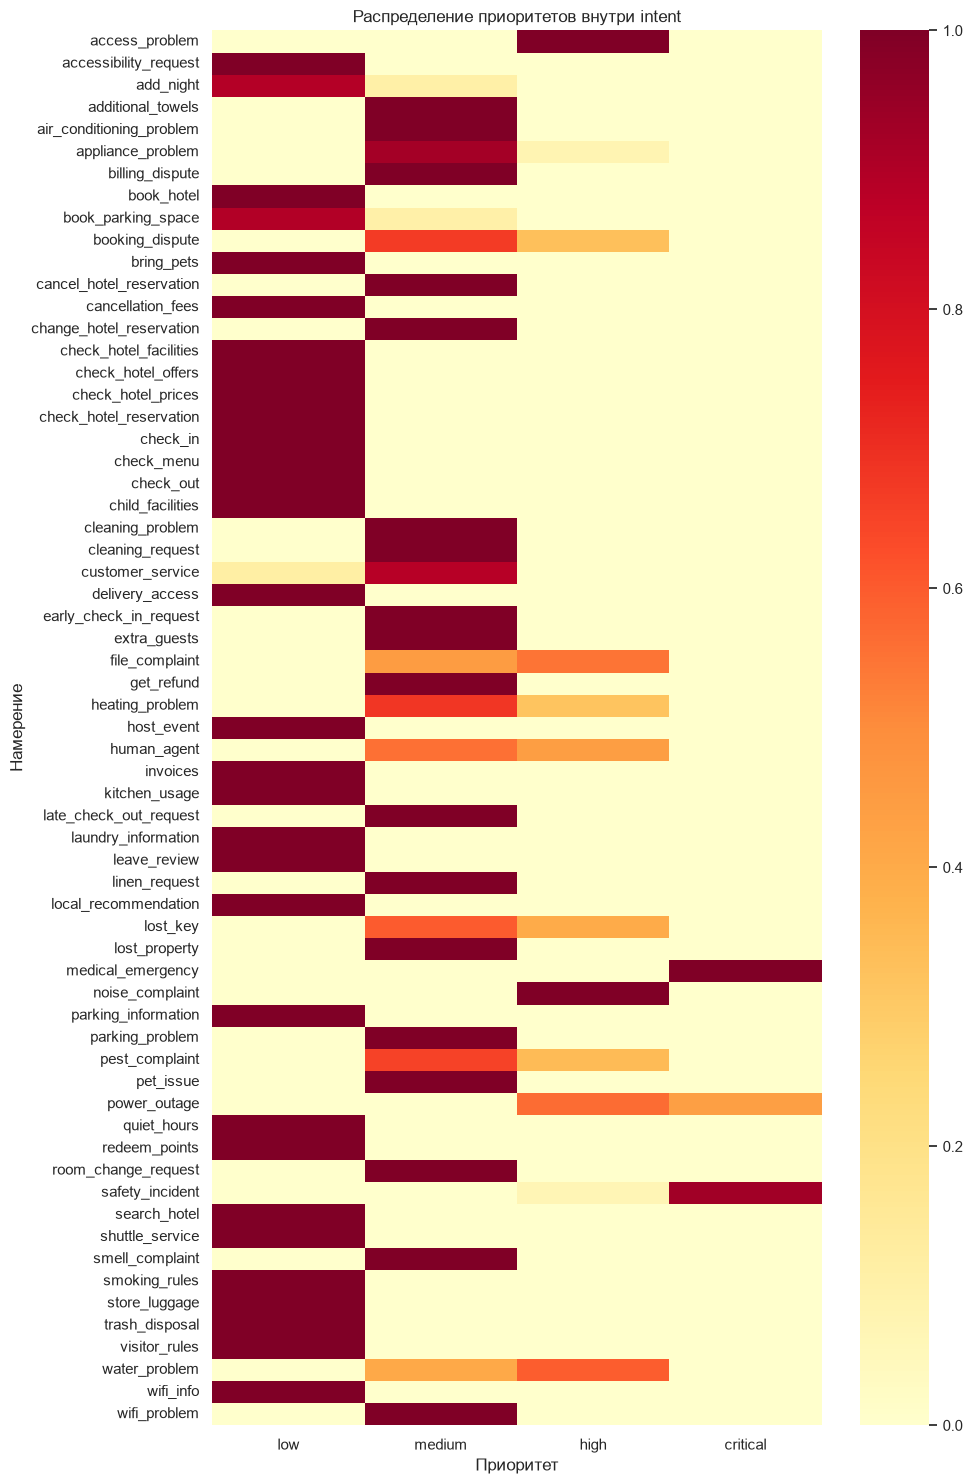

In [43]:
priority_by_intent = pd.crosstab(eda["intent"],eda["priority"],normalize="index").reindex(columns=PRIORITY_ORDER,fill_value=0)
fig, ax = plt.subplots(figsize=(10, 15))
sns.heatmap(priority_by_intent,cmap="YlOrRd",vmin=0,vmax=1,ax=ax)
ax.set_title("Распределение приоритетов внутри intent")
ax.set_xlabel("Приоритет")
ax.set_ylabel("Намерение")
plt.tight_layout()
plt.show()

Исходя из получившихся результатов анализа видно, что для 50 из 63 намерений, или 79,4% классов, представлен только один уровень приоритета. Оставшиеся 13 намерений содержат два уровня срочности.

Таким образом, вариативность приоритетов внутри большинства намерений крайне ограничена(результат согласуется с ранее установленной высокой ассоциацией между intent и priority — V Крамера составляет 0,8785)

С точки зрения ML это означает, что модель приоритизации может достичь высокой согласованности с существующей разметкой, преимущественно распознавая тип запроса. Однако есть и минусы у данного подхода, так как он не всегда позволит различать степень опасности конкретной ситуации. Например, техническая неисправность может иметь различную срочность в зависимости от того, препятствует ли она проживанию, создаёт ли риск безопасности и насколько быстро ситуация развивается.

### Анализ редкого критического класса

В задаче классификации приоритетов ошибки могут иметь различную практическую значимость.

Особенно важны случаи, когда обращение, требующее немедленного реагирования, ошибочно классифицируется как менее срочное.Поэтому необходимо отдельно исследовать представленность класса critical, его тематический состав и соотношение с другими уровнями приоритета.

Хотя общий анализ распределения приоритетов уже выполнен моим сокомандником, здесь акцент делается на последствиях дисбаланса для обучения и оценки ML-модели.

In [44]:
critical_df = eda.loc[eda["priority"] == "critical"].copy()
critical_count = len(critical_df)
critical_share = critical_count / len(eda)
critical_intents = (critical_df["intent"].value_counts().to_frame("Количество"))
print("Критических обращений:", critical_count)
print(f"Доля критического класса: {critical_share:.3%}")
display(critical_intents)
print("\nПримеры критических обращений:")
display(critical_df[["instruction","intent","needs_escalation"]].sample(n=min(12, len(critical_df)),random_state=RANDOM_STATE))

Критических обращений: 287
Доля критического класса: 0.820%


,Количество
intent,
safety_incident,124
medical_emergency,107
power_outage,56



Примеры критических обращений:


,instruction,intent,needs_escalation
25433,"Ребёнок обжёгся кипятком, срочно нужна помощь....",medical_emergency,1
33514,Нужна немедленная помощь. Дверь аварийного вых...,safety_incident,1
29706,С потолка течёт вода рядом с электропроводкой....,safety_incident,1
32058,Дверь аварийного выхода заблокирована. Это про...,safety_incident,1
32683,Нужна немедленная помощь. Человек без сознания...,medical_emergency,1
31448,Гость резко почувствовал сильное головокружени...,medical_emergency,1
28286,"Гостю стало плохо, он почти теряет сознание. В...",medical_emergency,1
27569,"Свет погас резко. В электрощитке слышно треск,...",power_outage,1
28766,Помогите быстро связаться с ответственными. У ...,medical_emergency,1
26198,Рядом есть другие гости. У пожилого родственни...,medical_emergency,1


Полученное распределение свидетельствует о тематической концентрации наиболее срочных запросов в ситуациях, связанных с безопасностью, медицинскими обстоятельствами и проблемы с техникой.

Одновременно наблюдается выраженный дисбаланс: класс critical существенно уступает по численности наиболее распространённым уровням приоритета. Следовательно жто приводит к подбору качественных метрик для оценки дальнейшей модели. Важно будет учесть, что классификатор может показывать высокую общую Accuracy, правильно обрабатывая многочисленные стандартные обращения, но при этом пропускать значительную часть критических ситуаций.

Поэтому для оценки модели приоритизации необходимо использовать не только Macro F1, но и отдельно рассчитывать Recall для класса critical, а также анализировать структуру ошибок.

## Часть 4 Предобработка данных для дальнейшего ML

### Очистка и нормализация текста

In [45]:
import re
import html
import unicodedata

def clean_guest_text(value):
    if pd.isna(value):
        return ""
    text = html.unescape(str(value))
    text = unicodedata.normalize("NFKC",text)
    text = text.replace("\u200b", "")
    text = text.replace("\ufeff", "")
    text = text.replace("\u00a0", " ")
    text = re.sub(r"\s+", " ", text)
    return text.strip()


def normalize_text_key(value):
    text = clean_guest_text(value)
    text = text.casefold().replace("ё", "е")
    text = re.sub(r"[^\w\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

In [46]:
# Создаём рабочую копию
prep = df.copy(deep=True)
prep["model_text"] = (prep["instruction"].map(clean_guest_text))
prep["text_key"] = (prep["model_text"].map(normalize_text_key))

# Приводим целевые переменные к корректным типам
for col in ["needs_escalation", "has_typos"]:
    prep[col] = pd.to_numeric(prep[col],errors="raise").astype("int8")

prep["intent"] = (prep["intent"].astype("string").str.strip())
prep["priority"] = (prep["priority"].astype("string").str.strip().str.lower())

# Проверка сохранения смысловых различий
assert (normalize_text_key("Не работает интернет")!= normalize_text_key("Работает интернет"))

assert prep["model_text"].str.len().gt(0).all()
assert prep["request_id"].is_unique
assert prep["intent"].notna().all()
assert prep["priority"].isin(PRIORITY_ORDER).all()

print("Исходных обращений:", len(df))
print("После очистки:", len(prep))

display(prep[["instruction", "model_text", "text_key"]].head(10))

Исходных обращений: 35000
После очистки: 35000


,instruction,model_text,text_key
0,"Чёрт возьми, не нахожу выставленные счета, пом...","Чёрт возьми, не нахожу выставленные счета, пом...",черт возьми не нахожу выставленные счета помог...
1,"Не нахожу выставленные счета, помогите. Где мн...","Не нахожу выставленные счета, помогите. Где мн...",не нахожу выставленные счета помогите где мне ...
2,Как скачать счета из личноо кабинета? Объяснит...,Как скачать счета из личноо кабинета? Объяснит...,как скачать счета из личноо кабинета объясните...
3,"Да что же это таке, подскажите, как получить к...","Да что же это таке, подскажите, как получить к...",да что же это таке подскажите как получить коп...
4,"Не нахожу выставленные счета, помогите. Что дл...","Не нахожу выставленные счета, помогите. Что дл...",не нахожу выставленные счета помогите что для ...
5,Где можно посмотреть мои счета за проживвание?...,Где можно посмотреть мои счета за проживвание?...,где можно посмотреть мои счета за проживвание ...
6,"Не нахожу выставленные счета, помогите. Можете...","Не нахожу выставленные счета, помогите. Можете...",не нахожу выставленные счета помогите можете п...
7,"Блин, мне нужно проверить счеат за проживание....","Блин, мне нужно проверить счеат за проживание....",блин мне нужно проверить счеат за проживание п...
8,"Не нахожу выставленные счета, помогите. Хотело...","Не нахожу выставленные счета, помогите. Хотело...",не нахожу выставленные счета помогите хотелось...
9,Как скачать счтеа из личного кабинета? Подскаж...,Как скачать счтеа из личного кабинета? Подскаж...,как скачать счтеа из личного кабинета подскажи...


### Формирование специализированных обучающих корпусов

In [47]:
# Анализ согласованности меток
label_groups = (prep.groupby("text_key").agg(n_intents=("intent", "nunique"),n_escalations=("needs_escalation", "nunique"),n_priorities=("priority", "nunique")))
# Добавляем индикаторы конфликтов
prep["intent_conflict"] = (prep["text_key"].map(label_groups["n_intents"]) > 1)
prep["escalation_conflict"] = (prep["text_key"].map(label_groups["n_escalations"]) > 1)
prep["priority_conflict"] = (prep["text_key"].map(label_groups["n_priorities"]) > 1)

# Корпус для Intent Classification
df_intent = (prep.loc[~prep["intent_conflict"]].sort_values(["text_key", "request_id"]).drop_duplicates("text_key").reset_index(drop=True).copy())
# Предварительный корпус для Escalation Classification
df_weak_escalation = (prep.loc[~prep["escalation_conflict"]].sort_values(["text_key", "request_id"]).drop_duplicates("text_key").reset_index(drop=True).copy())
# Предварительный корпус для Priority Classification
df_weak_priority = (prep.loc[~prep["priority_conflict"]].sort_values(["text_key", "request_id"]).drop_duplicates("text_key").reset_index(drop=True).copy())
approved_statuses = {"approved","verified","expert_verified"}

df_gold = prep.loc[prep["annotation_status"].isin(approved_statuses)].copy()

summary = pd.DataFrame({
    "Dataset": [
        "Полный очищенный корпус",
        "Intent Classification",
        "Weak Escalation",
        "Weak Priority",
        "Expert Verified"
    ],
    "Rows": [
        len(prep),
        len(df_intent),
        len(df_weak_escalation),
        len(df_weak_priority),
        len(df_gold)
    ]
})

display(summary)
assert df_intent["text_key"].is_unique
assert (df_intent["intent"].nunique()== prep["intent"].nunique())

,Dataset,Rows
0,Полный очищенный корпус,35000
1,Intent Classification,28800
2,Weak Escalation,28610
3,Weak Priority,28799
4,Expert Verified,0


In [48]:
from sklearn.model_selection import train_test_split

assert df_intent["scenario_group_id"].notna().all()
group_intent_count = (df_intent.groupby("scenario_group_id")["intent"].nunique())
assert group_intent_count.max() == 1
text_group_count = (prep.groupby("text_key")["scenario_group_id"].nunique())
assert text_group_count.max() == 1
groups = (df_intent.groupby("scenario_group_id").agg(intent=("intent", "first"),n_rows=("request_id", "size")).reset_index())
print("Всего сценарных групп:", len(groups))
print("Минимальное количество групп на intent:",groups["intent"].value_counts().min())

Всего сценарных групп: 902
Минимальное количество групп на intent: 12


In [49]:
train_groups, temp_groups = train_test_split(groups,test_size=0.30,stratify=groups["intent"],random_state=RANDOM_STATE)
val_groups, test_groups = train_test_split(temp_groups,test_size=0.50,stratify=temp_groups["intent"],random_state=RANDOM_STATE)

train_df = df_intent.loc[df_intent["scenario_group_id"].isin(train_groups["scenario_group_id"])].copy()
val_df = df_intent.loc[df_intent["scenario_group_id"].isin(val_groups["scenario_group_id"])].copy()

test_df = df_intent.loc[df_intent["scenario_group_id"].isin(test_groups["scenario_group_id"])].copy()

split_summary = pd.DataFrame({"Subset": ["Train", "Validation", "Test"],
                              "Rows": [len(train_df),len(val_df),len(test_df)],
                              "Intents": [
                                  train_df["intent"].nunique(),
                                  val_df["intent"].nunique(),
                                  test_df["intent"].nunique()],
                                  "Min examples per intent": [
                                      train_df["intent"].value_counts().min(),
                                      val_df["intent"].value_counts().min(),
                                      test_df["intent"].value_counts().min()]
})
display(split_summary)

,Subset,Rows,Intents,Min examples per intent
0,Train,20420,63,69
1,Validation,4436,63,17
2,Test,3944,63,13


In [50]:
import joblib
from pathlib import Path

root = globals().get("PROJECT_ROOT",globals().get("BASE", Path.cwd()))
processed_dir = Path(root) / "data" / "processed"
processed_dir.mkdir(parents=True,exist_ok=True)

train_df.to_csv(processed_dir / "intent_train.csv",sep=";",index=False,encoding="utf-8-sig")
val_df.to_csv(processed_dir / "intent_val.csv",sep=";",index=False,encoding="utf-8-sig")
test_df.to_csv(processed_dir / "intent_test.csv",sep=";",index=False,encoding="utf-8-sig")

## Часть 5. Семантический анализ текстовых эмбеддингов

**Анализ эмбеддингов обращений.**

Исследовательские вопросы:
1. Какие обращения и намерения близки в семантическом пространстве?
2. Насколько близость определяется сценарными шаблонами и повторениями?
3. Какие похожие пары и пересечения классов требуют ручной проверки?
4. Как отличаются обычный RuBERT и модель эмбеддингов предложений SBERT?

Сравниваем [DeepPavlov/rubert-base-cased](https://huggingface.co/DeepPavlov/rubert-base-cased)
и [ai-forever/sbert_large_nlu_ru](https://huggingface.co/ai-forever/sbert_large_nlu_ru).
Для обеих: mean pooling последнего скрытого слоя с attention mask (включая специальные,
исключая padding-токены), max_length=128 и L2-нормализация. SBERT подключается через
Sentence Transformers с явно заданным mean pooling. Размеры и обучение моделей различаются:
это сравнение готовых решений, а не изолированный эксперимент над архитектурой.




In [51]:
# Проверка локального kernel. Зависимости устанавливаются заранее: uv sync --dev.
import importlib.util
import sys

embedding_missing_packages = [name for name in ['torch', 'transformers', 'sentence_transformers']
                              if importlib.util.find_spec(name) is None]
print('Python kernel:', sys.executable)
if embedding_missing_packages:
    raise RuntimeError('Не установлены зависимости: ' + ', '.join(embedding_missing_packages)
                       + '. Выполните uv sync --dev и выберите kernel .venv.')


Python kernel: /Users/leonidbeleckij/Documents/HSE/Year project/rental-ai-assistant/.venv/bin/python


### 5.1. Выбор текстов и ограничения разметки

Вход — только русские `model_text` из существующей `prep`. Стоп-слова, отрицания, регистр,
пунктуация и опечатки дополнительно не удаляются. Каждая точная копия очищенного текста
кодируется один раз; исходные request_id и метаданные сохраняются в таблице соответствия.
Нормализованный `text_key` используется только для фильтрации соседей, но не как вход модели.

`intent` и остальные метки не подаются энкодерам. Они нужны для описания геометрии после
расчёта. Все строки текущего файла отмечены как синтетические и требуют ручной проверки.
Часть русских текстов — перефразирования по intent, а не буквальный перевод английского.
Поэтому английские оригиналы не используем как эталонные параллельные пары.


In [52]:
import hashlib
import json
from collections import deque
from pathlib import Path

import numpy as np
import pandas as pd


def prepare_embedding_rows(prepared):
    required = {
        "request_id", "model_text", "text_key", "intent", "category",
        "scenario_group_id", "source_dataset", "noise_type", "language",
    }
    missing = required - set(prepared.columns)
    if missing:
        raise ValueError(f"Для части 5 не хватает колонок prep: {sorted(missing)}")
    rows = prepared.loc[prepared["language"].eq("ru"), sorted(required)].copy()
    if rows.empty or rows[list(required)].isna().any().any():
        raise ValueError("Нет русских обращений либо обязательные поля содержат пропуски.")
    if not rows["request_id"].is_unique or not rows["model_text"].str.strip().ne("").all():
        raise ValueError("request_id должны быть уникальны, model_text — непустыми.")
    rows = rows.sort_values("request_id", kind="stable").reset_index(drop=True)
    groups = rows.groupby("model_text", sort=False)
    for column in ["intent", "scenario_group_id", "text_key"]:
        if groups[column].nunique().gt(1).any():
            raise ValueError(f"Одинаковые тексты имеют разные {column}; сначала разберите конфликт.")
    unique = rows.drop_duplicates("model_text").reset_index(drop=True).copy()
    unique["embedding_index"] = np.arange(len(unique))
    unique["multiplicity"] = unique["model_text"].map(groups.size()).astype(int)
    origins = groups["source_dataset"].agg(lambda s: sorted(set(s)))
    unique["source_datasets"] = unique["model_text"].map(origins)
    unique["source_display"] = unique["source_datasets"].map(
        lambda values: values[0] if len(values) == 1 else "несколько источников"
    )
    unique["noise_types"] = unique["model_text"].map(
        groups["noise_type"].agg(lambda s: sorted(set(s)))
    )
    mapping = rows.merge(
        unique[["model_text", "embedding_index"]], on="model_text", how="left", validate="many_to_one"
    )
    assert mapping["embedding_index"].notna().all()
    assert unique["multiplicity"].sum() == len(rows)
    return unique, mapping


def embedding_cache_key(texts, ids, model_id, revision, max_length, versions, execution_device=None):
    spec = {
        "schema": 1, "texts": list(texts), "ids": list(ids), "model_id": model_id,
        "revision": revision, "max_length": max_length,
        "pooling": "last_hidden_state_attention_mask_mean_including_special_tokens",
        "normalization": "l2", "versions": dict(versions), "execution_device": execution_device,
    }
    return hashlib.sha256(json.dumps(spec, ensure_ascii=False, sort_keys=True).encode()).hexdigest()


def validate_vectors(vectors, n_rows):
    if vectors.ndim != 2 or vectors.shape[0] != n_rows or vectors.shape[1] < 1:
        raise ValueError("Размер массива не соответствует порядку текстов.")
    if not np.isfinite(vectors).all():
        raise ValueError("В эмбеддингах обнаружены NaN/Inf.")
    if not np.allclose(np.linalg.norm(vectors, axis=1), 1.0, atol=1e-4):
        raise ValueError("Эмбеддинги должны быть ненулевыми и L2-нормированными.")


def save_embedding_cache(folder, vectors, metadata, ids):
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    validate_vectors(vectors, len(ids))
    temp = folder / "vectors.tmp.npy"
    np.save(temp, vectors.astype(np.float32), allow_pickle=False)
    checksum = hashlib.sha256(temp.read_bytes()).hexdigest()
    temp.replace(folder / "vectors.npy")
    payload = {**metadata, "ids": list(ids), "vectors_sha256": checksum}
    temp_meta = folder / "metadata.tmp.json"
    temp_meta.write_text(json.dumps(payload, ensure_ascii=False, indent=2))
    temp_meta.replace(folder / "metadata.json")


def load_embedding_cache(folder, key, ids):
    folder = Path(folder)
    if not (folder / "metadata.json").exists() or not (folder / "vectors.npy").exists():
        return None
    metadata = json.loads((folder / "metadata.json").read_text())
    if metadata.get("cache_key") != key or metadata.get("ids") != list(ids):
        raise ValueError("Кеш не соответствует текстам, параметрам или порядку строк.")
    if hashlib.sha256((folder / "vectors.npy").read_bytes()).hexdigest() != metadata["vectors_sha256"]:
        raise ValueError("Контрольная сумма кеша не совпадает; удалите повреждённый кеш.")
    vectors = np.load(folder / "vectors.npy", allow_pickle=False)
    validate_vectors(vectors, len(ids))
    return vectors, metadata


def encode_adaptive(texts, batch_size, encode_batch, oom_exception, on_oom):
    if batch_size < 1:
        raise ValueError("batch_size должен быть положительным.")
    blocks, position, reductions = [], 0, []
    while position < len(texts):
        try:
            block = np.asarray(encode_batch(texts[position:position + batch_size]), dtype=np.float32)
            validate_vectors(block, min(batch_size, len(texts) - position))
        except oom_exception as error:
            on_oom()
            if batch_size == 1:
                raise RuntimeError("Недостаточно памяти устройства даже при batch_size=1. Освободите память или выберите CPU.") from error
            batch_size = max(1, batch_size // 2)
            reductions.append(batch_size)
            continue
        blocks.append(block)
        position += len(block)
    return np.concatenate(blocks), batch_size, reductions


def visualization_indices(rows, seed=42, per_group=3):
    rng = np.random.default_rng(seed)
    selected = []
    for _, group in rows.groupby("scenario_group_id", sort=True):
        selected.extend(rng.choice(group.index.to_numpy(), min(per_group, len(group)), replace=False))
    return np.sort(np.asarray(selected, dtype=int))


def balanced_query_indices(rows, limit=1000, seed=42):
    rng = np.random.default_rng(seed)
    by_intent = {}
    for intent, subset in rows.groupby("intent", sort=True):
        queues = []
        for _, group in subset.groupby("scenario_group_id", sort=True):
            indices = group.index.to_numpy().copy()
            rng.shuffle(indices)
            queues.append(deque(indices.tolist()))
        rng.shuffle(queues)
        by_intent[intent] = deque(queues)
    result = []
    while by_intent and len(result) < limit:
        for intent in list(by_intent):
            queue = by_intent[intent]
            group = queue.popleft()
            result.append(group.popleft())
            if group:
                queue.append(group)
            if not queue:
                del by_intent[intent]
            if len(result) == limit:
                break
    return np.asarray(result, dtype=int)


def nearest_neighbors(vectors, rows, queries, k=5, exclude_scenario=False,
                      different_intent=False, block_size=128, score_block=None):
    validate_vectors(vectors, len(rows))
    if k < 1 or block_size < 1:
        raise ValueError("k и block_size должны быть положительными.")
    queries = np.asarray(queries, dtype=int)
    if np.any((queries < 0) | (queries >= len(rows))):
        raise ValueError("Некорректные индексы запросов.")
    groups = rows["scenario_group_id"].to_numpy()
    keys = rows["text_key"].to_numpy()
    labels = rows["intent"].to_numpy()
    neighbors = np.full((len(queries), k), -1, dtype=int)
    similarities = np.full((len(queries), k), np.nan, dtype=np.float32)
    effective_k = min(k, len(rows))
    for start in range(0, len(queries), block_size):
        block = queries[start:start + block_size]
        scores = (vectors[block] @ vectors.T) if score_block is None else score_block(block)
        scores = np.asarray(scores, dtype=np.float32).copy()
        if scores.shape != (len(block), len(rows)) or not np.isfinite(scores).all():
            raise ValueError("Некорректный блок similarities.")
        scores = np.clip(scores, -1.0, 1.0)
        scores[np.arange(len(block)), block] = -np.inf
        if exclude_scenario:
            scores[(groups[block, None] == groups[None, :]) | (keys[block, None] == keys[None, :])] = -np.inf
        if different_intent:
            scores[labels[block, None] == labels[None, :]] = -np.inf
        candidates = np.argpartition(-scores, effective_k - 1, axis=1)[:, :effective_k]
        for offset, indices in enumerate(candidates):
            indices = indices[np.lexsort((indices, -scores[offset, indices]))]
            valid = np.isfinite(scores[offset, indices])
            indices = indices[valid]
            target = start + offset
            neighbors[target, :len(indices)] = indices
            similarities[target, :len(indices)] = scores[offset, indices]
    return neighbors, similarities


def neighbor_agreement(rows, queries, neighbors):
    labels = rows["intent"].to_numpy()
    valid = neighbors >= 0
    hits = (labels[np.maximum(neighbors, 0)] == labels[np.asarray(queries), None]) & valid
    denominator = valid.sum(axis=1)
    per_query = np.divide(hits.sum(axis=1), denominator,
                          out=np.full(len(queries), np.nan), where=denominator > 0)
    table = pd.DataFrame({"intent": labels[queries], "agreement": per_query, "valid_neighbors": denominator})
    return {
        "micro_agreement": float(hits.sum() / valid.sum()) if valid.any() else np.nan,
        "macro_intent_agreement": float(table.groupby("intent")["agreement"].mean().mean()),
        "queries_with_neighbors": int((denominator > 0).sum()),
        "mean_valid_neighbors": float(denominator.mean()) if len(denominator) else np.nan,
    }, table


def neighbor_examples(rows, queries, neighbors, similarities):
    records = []
    for i, query in enumerate(queries):
        for rank, neighbor in enumerate(neighbors[i], 1):
            if neighbor < 0:
                continue
            records.append({
                "query_id": rows.iloc[query]["request_id"], "query": rows.iloc[query]["model_text"],
                "query_intent": rows.iloc[query]["intent"], "query_group": rows.iloc[query]["scenario_group_id"],
                "rank": rank, "neighbor": rows.iloc[neighbor]["model_text"],
                "neighbor_intent": rows.iloc[neighbor]["intent"],
                "neighbor_group": rows.iloc[neighbor]["scenario_group_id"],
                "similarity": float(similarities[i, rank - 1]),
            })
    return pd.DataFrame(records)


def intent_centroids(vectors, rows):
    names, centroids = [], []
    for intent, subset in rows.groupby("intent", sort=True):
        group_means = [vectors[group.index].mean(axis=0)
                       for _, group in subset.groupby("scenario_group_id", sort=True)]
        centroid = np.mean(group_means, axis=0)
        norm = np.linalg.norm(centroid)
        if not np.isfinite(norm) or norm < 1e-12:
            raise ValueError(f"Не определён центроид {intent}.")
        names.append(intent)
        centroids.append(centroid / norm)
    centroids = np.asarray(centroids)
    return names, centroids, np.clip(centroids @ centroids.T, -1.0, 1.0)


def closest_intents(names, similarities, limit=20):
    pairs = [{"intent_a": names[i], "intent_b": names[j], "similarity": float(similarities[i, j])}
             for i in range(len(names)) for j in range(i + 1, len(names))]
    return pd.DataFrame(sorted(pairs, key=lambda p: (-p["similarity"], p["intent_a"], p["intent_b"]))[:limit])


def closest_pairs(rows, queries, neighbors, similarities, limit=20):
    pairs = {}
    for i, query in enumerate(queries):
        for j, neighbor in enumerate(neighbors[i]):
            if neighbor < 0:
                continue
            a, b = sorted((int(query), int(neighbor)))
            pairs[(a, b)] = max(pairs.get((a, b), -np.inf), float(similarities[i, j]))
    records = []
    for (a, b), score in sorted(pairs.items(), key=lambda item: (-item[1], item[0]))[:limit]:
        records.append({
            "request_a": rows.iloc[a]["request_id"], "text_a": rows.iloc[a]["model_text"],
            "intent_a": rows.iloc[a]["intent"], "group_a": rows.iloc[a]["scenario_group_id"],
            "request_b": rows.iloc[b]["request_id"], "text_b": rows.iloc[b]["model_text"],
            "intent_b": rows.iloc[b]["intent"], "group_b": rows.iloc[b]["scenario_group_id"],
            "similarity": score,
        })
    return pd.DataFrame(records)


In [53]:
if 'prep' not in globals():
    raise RuntimeError('Сначала выполните часть 4: нужны prep, model_text и text_key.')

embedding_rows, embedding_mapping = prepare_embedding_rows(prep)
embedding_texts = embedding_rows['model_text'].tolist()
display(pd.DataFrame({
    'Показатель': ['Исходных строк prep', 'Русских строк', 'Уникальных model_text',
                   'Сценарных групп', 'Повторных включений одинаковых текстов'],
    'Количество': [len(prep), len(embedding_mapping), len(embedding_rows),
                   embedding_rows['scenario_group_id'].nunique(),
                   len(embedding_mapping) - len(embedding_rows)],
}))
display(embedding_rows[['request_id', 'model_text', 'multiplicity', 'intent',
                        'scenario_group_id', 'source_datasets', 'noise_types']].head())
for embedding_column in ['is_synthetic', 'annotation_status', 'localization_method']:
    if embedding_column in prep:
        print(embedding_column, prep[embedding_column].value_counts(dropna=False).to_dict())


,Показатель,Количество
0,Исходных строк prep,35000
1,Русских строк,35000
2,Уникальных model_text,28800
3,Сценарных групп,902
4,Повторных включений одинаковых текстов,6200


,request_id,model_text,multiplicity,intent,scenario_group_id,source_datasets,noise_types
0,bitext_00001,"Чёрт возьми, не нахожу выставленные счета, пом...",1,invoices,bitext__invoices__29,[bitext_hospitality],[missing_letter]
1,bitext_00002,"Не нахожу выставленные счета, помогите. Где мн...",1,invoices,bitext__invoices__29,[bitext_hospitality],[transposed_letters]
2,bitext_00003,Как скачать счета из личноо кабинета? Объяснит...,1,invoices,bitext__invoices__44,[bitext_hospitality],[missing_letter]
3,bitext_00004,"Да что же это таке, подскажите, как получить к...",1,invoices,bitext__invoices__67,[bitext_hospitality],[missing_letter]
4,bitext_00005,"Не нахожу выставленные счета, помогите. Что дл...",2,invoices,bitext__invoices__29,[bitext_hospitality],[none]


is_synthetic {1: 35000}
annotation_status {'requires_manual_review': 35000}
localization_method {'rule_based_intent_paraphrase_not_literal_translation': 25000, 'original_ru_synthetic_scenario': 10000}


### 5.2. Получение эмбеддингов и проверка кеша

Модели запускаются последовательно. Для каждой фиксируются точная ревизия, версии пакетов,
устройство, начальный и фактический batch size. Используются `eval()` и `inference_mode()`.
При нехватке памяти устройства пакет уменьшается вдвое без пропуска или повторного добавления строк.


Тексты усечены, если длина с особыми токенами превышает 128; доли показываются по уникальным
текстам и исходным русским строкам. 

In [54]:
import gc
import importlib.metadata
import platform
import time

import torch
import torch.nn.functional as torch_f
from huggingface_hub import HfApi
from transformers import AutoModel, AutoTokenizer
from sentence_transformers import SentenceTransformer, models as st_models


def mean_pool_last_hidden(hidden, attention_mask):
    mask = attention_mask.unsqueeze(-1).to(hidden.dtype)
    return (hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-9)


class EmbeddingDeviceOOM(RuntimeError):
    pass


def select_embedding_device(preferred="auto"):
    if preferred not in {"auto", "cuda", "mps", "cpu"}:
        raise ValueError("EMBEDDING_DEVICE: допустимы auto, cuda, mps, cpu.")
    cuda = torch.cuda.is_available()
    mps_backend = getattr(torch.backends, "mps", None)
    mps = bool(mps_backend is not None and mps_backend.is_available())
    if preferred == "auto":
        return "cuda" if cuda else "mps" if mps else "cpu"
    if preferred == "cuda" and not cuda:
        raise RuntimeError("CUDA недоступна. Установите EMBEDDING_DEVICE='auto' или 'cpu'.")
    if preferred == "mps" and not mps:
        raise RuntimeError("MPS недоступен. Установите EMBEDDING_DEVICE='cpu'.")
    return preferred


def synchronize_embedding_device(device):
    if device == "cuda":
        torch.cuda.synchronize()
    elif device == "mps":
        torch.mps.synchronize()


def clear_embedding_device(device):
    if device == "cuda":
        torch.cuda.empty_cache()
    elif device == "mps":
        torch.mps.empty_cache()


def embedding_device_name(device):
    if device == "cuda":
        return torch.cuda.get_device_name(0)
    if device == "mps":
        return f"Apple Silicon / MPS ({platform.machine()})"
    return f"CPU ({platform.machine()})"


def is_embedding_oom(error):
    message = str(error).casefold()
    return any(part in message for part in [
        "out of memory", "not enough memory", "can't allocate memory", "cannot allocate memory",
    ])


def calculate_model_embeddings(spec, embedding_rows, cache_root, max_length=128):
    device = select_embedding_device(spec.get("device", "auto"))
    texts = embedding_rows["model_text"].tolist()
    ids = embedding_rows["request_id"].tolist()
    versions = {name: importlib.metadata.version(name)
                for name in ["torch", "transformers", "sentence-transformers", "numpy"]}
    # Revision is resolved before downloading weights; the resolved SHA is used everywhere.
    revision = HfApi().model_info(spec["model_id"]).sha
    if not revision:
        raise RuntimeError("Не удалось определить точную ревизию модели.")
    key = embedding_cache_key(texts, ids, spec["model_id"], revision, max_length, versions, execution_device=device)
    folder = Path(cache_root) / spec["name"] / key
    cached = load_embedding_cache(folder, key, ids)
    if cached is not None:
        vectors, metadata = cached
        print(f'{spec["name"]}: загружен проверенный кеш {folder}')
        return vectors, {**metadata, "loaded_from_cache": True}

    model = tokenizer = None
    try:
        if spec["kind"] == "rubert":
            tokenizer = AutoTokenizer.from_pretrained(spec["model_id"], revision=revision)
            model = AutoModel.from_pretrained(spec["model_id"], revision=revision).to(device)
        else:
            transformer = st_models.Transformer(
                spec["model_id"], max_seq_length=max_length,
                model_args={"revision": revision}, tokenizer_args={"revision": revision},
                config_args={"revision": revision},
            )
            pooling = st_models.Pooling(
                transformer.get_word_embedding_dimension(), pooling_mode_mean_tokens=True,
                pooling_mode_cls_token=False, pooling_mode_max_tokens=False,
            )
            model = SentenceTransformer(modules=[transformer, pooling], device=device)
            del transformer, pooling
            tokenizer = model.tokenizer
        model.eval()

        token_lengths = []
        for start in range(0, len(texts), 256):
            tokens = tokenizer(texts[start:start + 256], padding=False, truncation=False,
                               add_special_tokens=True)
            token_lengths.extend(map(len, tokens["input_ids"]))

        def _encode_batch(batch):
            with torch.inference_mode():
                if spec["kind"] == "rubert":
                    encoded = tokenizer(batch, padding=True, truncation=True,
                                        max_length=max_length, return_tensors="pt")
                    encoded = {name: value.to(device) for name, value in encoded.items()}
                    hidden = model(**encoded).last_hidden_state
                    pooled = mean_pool_last_hidden(hidden, encoded["attention_mask"])
                    return torch_f.normalize(pooled, p=2, dim=1).float().cpu().numpy()
                return model.encode(
                    batch, batch_size=len(batch), device=device, show_progress_bar=False,
                    convert_to_numpy=True, normalize_embeddings=True,
                ).astype(np.float32)

        def encode_batch(batch):
            try:
                return _encode_batch(batch)
            except RuntimeError as error:
                if is_embedding_oom(error):
                    raise EmbeddingDeviceOOM(str(error)) from None
                raise

        # Warm-up is excluded from timing and also reports a clear batch_size=1 failure.
        encode_adaptive(texts[:1], 1, encode_batch, EmbeddingDeviceOOM, lambda: clear_embedding_device(device))
        synchronize_embedding_device(device)
        start = time.perf_counter()
        vectors, final_batch_size, reductions = encode_adaptive(
            texts, spec["batch_size"], encode_batch,
            EmbeddingDeviceOOM, lambda: clear_embedding_device(device),
        )
        synchronize_embedding_device(device)
        elapsed = time.perf_counter() - start
        validate_vectors(vectors, len(texts))
        metadata = {
            "cache_key": key, "model_id": spec["model_id"], "revision": revision,
            "pooling": "attention_mask_mean_including_special_tokens", "normalization": "l2",
            "max_length": max_length, "versions": versions, "python": platform.python_version(),
            "rows": len(texts), "dimensions": int(vectors.shape[1]),
            "encoding_seconds": elapsed, "device": device, "device_name": embedding_device_name(device),
            "initial_batch_size": spec["batch_size"], "final_batch_size": final_batch_size,
            "oom_batch_reductions": reductions, "token_lengths": token_lengths,
            "loaded_from_cache": False,
        }
        save_embedding_cache(folder, vectors, metadata, ids)
        print(f'{spec["name"]}: {vectors.shape}, {elapsed:.1f} с; устройство: {metadata["device_name"]}')
        return vectors, metadata
    finally:
        del model, tokenizer
        gc.collect()
        clear_embedding_device(device)


def make_embedding_score_blocks(vectors, device="auto"):
    """Use bounded matrix blocks on CUDA/MPS; numpy handles the CPU path."""
    device = select_embedding_device(device)
    if device == "cpu":
        return None
    device_vectors = torch.as_tensor(vectors, dtype=torch.float32, device=device)

    def score_block(indices):
        with torch.inference_mode():
            result = device_vectors[torch.as_tensor(indices, device=device)] @ device_vectors.T
            return result.cpu().numpy()

    return score_block


/Users/leonidbeleckij/Documents/HSE/Year project/rental-ai-assistant/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/var/folders/px/lq6txpp90pb8spgckpkw2br40000gn/T/ipykernel_47396/2224361086.py:10: DeprecationWarning: Importing from 'sentence_transformers.models' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.modules' instead.
  from sentence_transformers import SentenceTransformer, models as st_models


In [55]:
EMBEDDING_SEED = 42
EMBEDDING_DEVICE = globals().get("EMBEDDING_DEVICE", "auto")
embedding_device = select_embedding_device(EMBEDDING_DEVICE)
print("Устройство:", embedding_device_name(embedding_device))
embedding_batch_sizes = {"cuda": (32, 16), "mps": (16, 8), "cpu": (8, 4)}[embedding_device]
EMBEDDING_MAX_LENGTH = 128
embedding_project_root = Path(BASE).resolve()
embedding_cache_root = Path(globals().get(
    'EMBEDDING_CACHE_ROOT', embedding_project_root / 'artifacts' / 'text_embeddings'
))
embedding_results_dir = embedding_project_root / 'artifacts' / 'text_embeddings' / 'analysis'
embedding_results_dir.mkdir(parents=True, exist_ok=True)
embedding_model_specs = [
    {'name': 'RuBERT', 'model_id': 'DeepPavlov/rubert-base-cased', 'kind': 'rubert', 'batch_size': embedding_batch_sizes[0], 'device': embedding_device},
    {'name': 'SBERT-ru', 'model_id': 'ai-forever/sbert_large_nlu_ru', 'kind': 'sbert', 'batch_size': embedding_batch_sizes[1], 'device': embedding_device},
]
embedding_vectors, embedding_metadata = {}, {}
for embedding_spec in embedding_model_specs:
    embedding_name = embedding_spec['name']
    embedding_vectors[embedding_name], embedding_metadata[embedding_name] = calculate_model_embeddings(
        embedding_spec, embedding_rows, embedding_cache_root, EMBEDDING_MAX_LENGTH
    )

embedding_technical_rows = []
for embedding_name, embedding_array in embedding_vectors.items():
    embedding_meta = embedding_metadata[embedding_name]
    embedding_lengths = np.asarray(embedding_meta['token_lengths'])
    embedding_cut = embedding_lengths > EMBEDDING_MAX_LENGTH
    embedding_technical_rows.append({
        'Модель': embedding_name, 'Размерность': embedding_array.shape[1],
        'Уникальных текстов': len(embedding_array),
        'Кодирование, с': embedding_meta['encoding_seconds'],
        'Усечение уникальных, доля': float(embedding_cut.mean()),
        'Усечение исходных строк, доля': float(np.average(embedding_cut, weights=embedding_rows['multiplicity'])),
        'Устройство исходного расчёта': embedding_meta.get('device_name', embedding_meta.get('gpu', 'не указано')),
        'Batch size итоговый': embedding_meta['final_batch_size'],
        'Из кеша': embedding_meta['loaded_from_cache'],
        'Ревизия': embedding_meta['revision'],
    })
embedding_technical = pd.DataFrame(embedding_technical_rows).set_index('Модель')
display(embedding_technical)


Устройство: Apple Silicon / MPS (arm64)


Some weights of the model checkpoint at DeepPavlov/rubert-base-cased were not used when initializing BertModel: ['cls.predictions.bias', 'cls.predictions.decoder.bias', 'cls.predictions.decoder.weight', 'cls.predictions.transform.LayerNorm.bias', 'cls.predictions.transform.LayerNorm.weight', 'cls.predictions.transform.dense.bias', 'cls.predictions.transform.dense.weight', 'cls.seq_relationship.bias', 'cls.seq_relationship.weight']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


RuBERT: (28800, 768), 82.7 с; устройство: Apple Silicon / MPS (arm64)


The Transformer `model_args` argument was renamed and is now deprecated, please use `model_kwargs` instead.
The Transformer `tokenizer_args` argument was renamed and is now deprecated, please use `processor_kwargs` instead.
The Transformer `config_args` argument was renamed and is now deprecated, please use `config_kwargs` instead.
/var/folders/px/lq6txpp90pb8spgckpkw2br40000gn/T/ipykernel_47396/2224361086.py:96: FutureWarning: The `get_word_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  transformer.get_word_embedding_dimension(), pooling_mode_mean_tokens=True,
/Users/leonidbeleckij/Documents/HSE/Year project/rental-ai-assistant/.venv/lib/python3.12/site-packages/sentence_transformers/util/decorators.py:41: FutureWarning: The `pooling_mode_mean_tokens`, `pooling_mode_cls_token`, `pooling_mode_max_tokens` argument(s) are deprecated. Please use `pooling_mode` instead.
  return func(*args, **kwargs)


SBERT-ru: (28800, 1024), 253.7 с; устройство: Apple Silicon / MPS (arm64)


,Размерность,Уникальных текстов,"Кодирование, с","Усечение уникальных, доля","Усечение исходных строк, доля",Устройство исходного расчёта,Batch size итоговый,Из кеша,Ревизия
Модель,,,,,,,,,
RuBERT,768,28800,82.706212,0.0,0.0,Apple Silicon / MPS (arm64),16,False,4036cab694767a299f2b9e6492909664d9414229
SBERT-ru,1024,28800,253.748898,0.0,0.0,Apple Silicon / MPS (arm64),8,False,89deeaa197d9d146e5763ac1f5fe32bf66817126


### 5.3. PCA и t-SNE на одинаковой выборке

Берём не более трёх уникальных текстов из каждой сценарной группы, seed=42: это ограничивает
влияние многократных шаблонных вариантов. Одинаковые request_id используются у обеих моделей.
PCA показывает линейную проекцию и объяснённую дисперсию; t-SNE рассчитывается после PCA до 50
измерений. Perplexity=30, seed=42. Для очень маленькой выборки t-SNE явно пропускается.

Раскраска не участвует в построении проекции. Графики по intent показывают десять самых
частых намерений и «остальные»; вторая колонка показывает происхождение текста.
Оси двух моделей не сопоставимы напрямую. Отдельные островки на t-SNE не доказывают
существование естественных классов или пригодность модели для RAG.


Для проекций: 2705 Для соседей: 1000


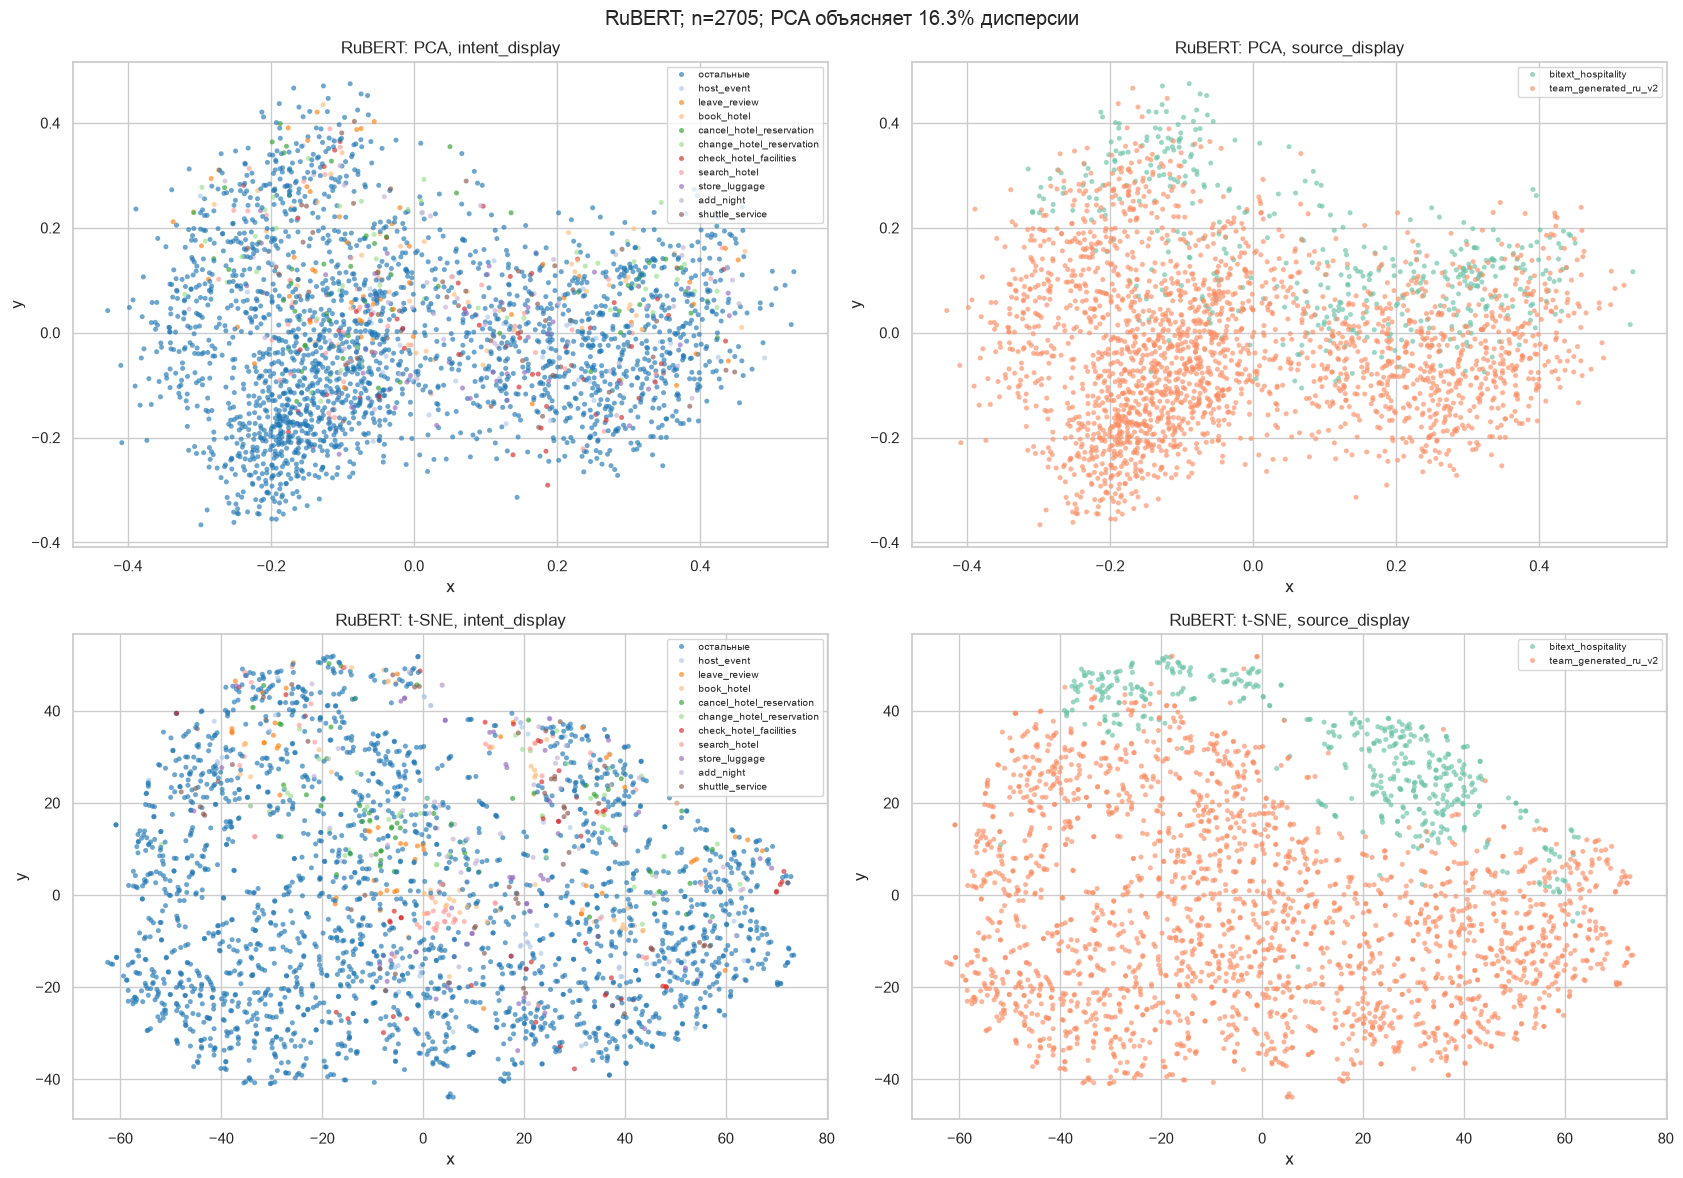

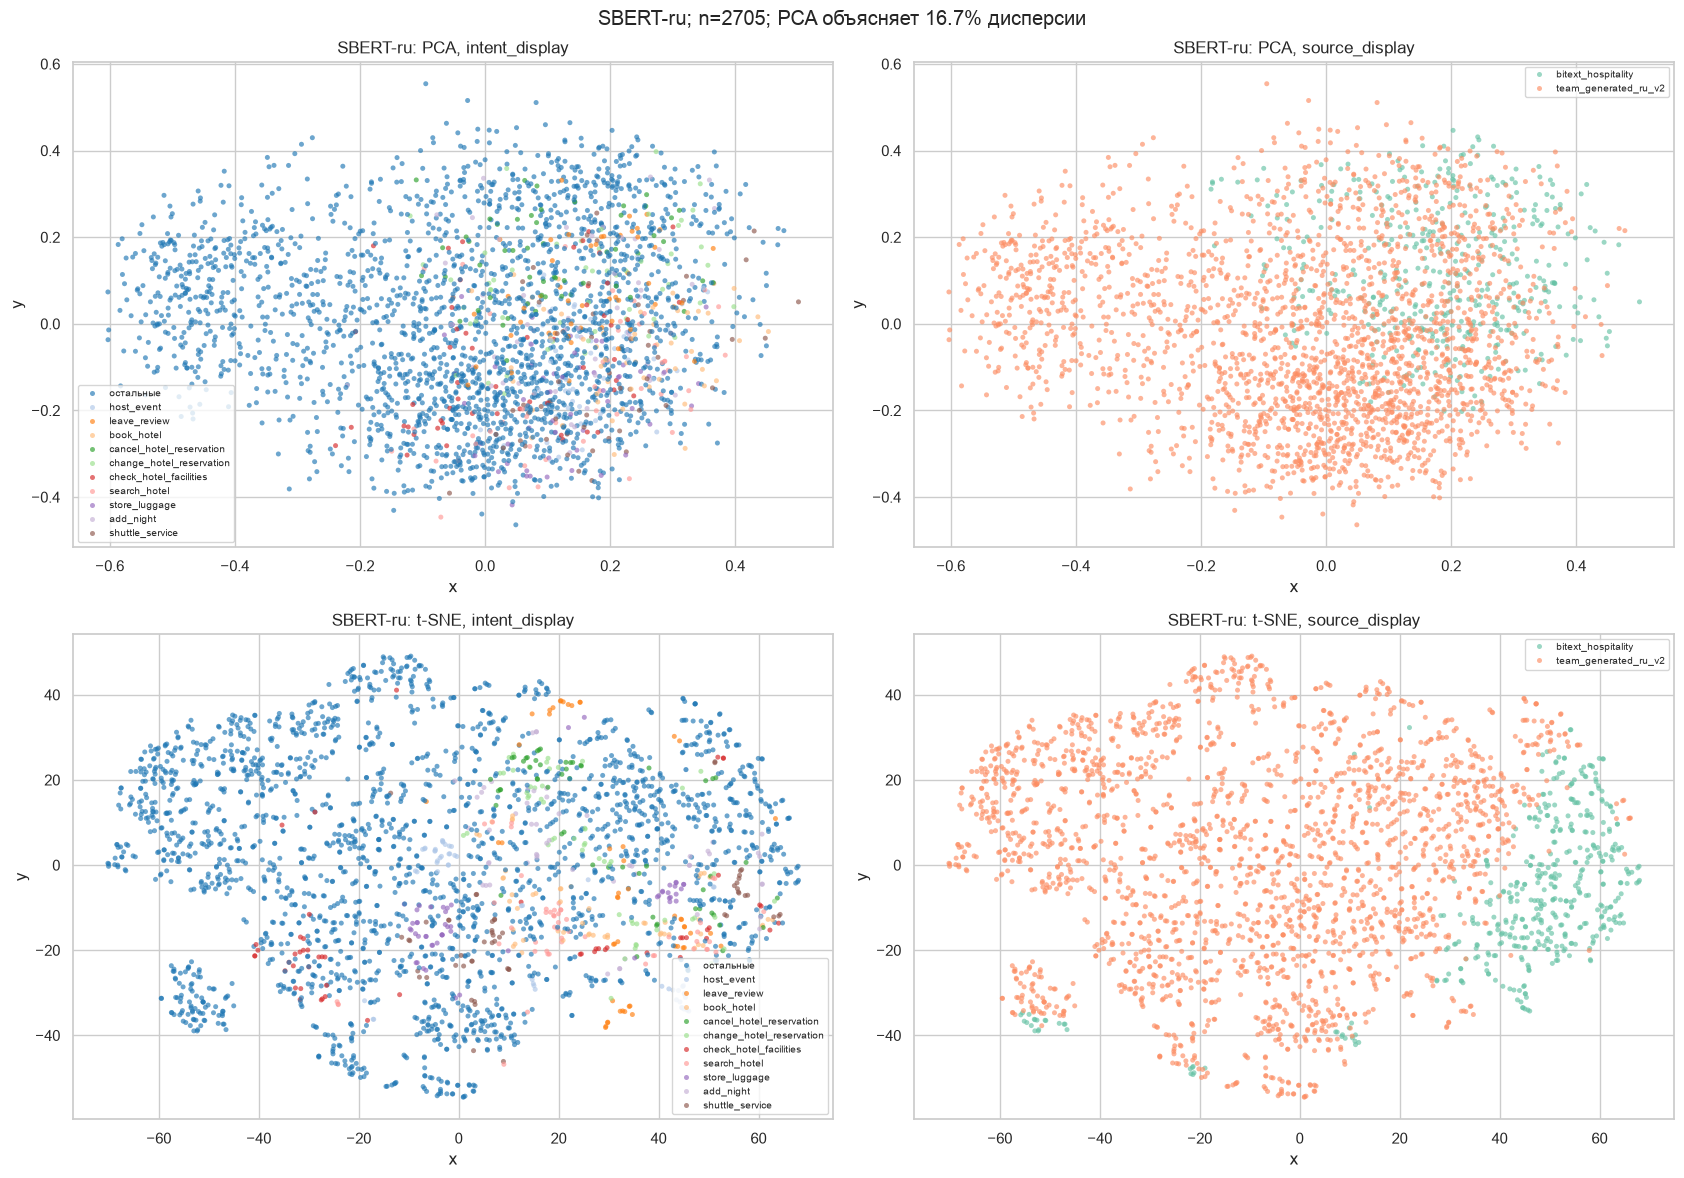

In [56]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns

embedding_visual_indices = visualization_indices(embedding_rows, EMBEDDING_SEED)
embedding_queries = balanced_query_indices(embedding_rows, 1000, EMBEDDING_SEED)
embedding_top_intents = set(embedding_rows['intent'].value_counts().head(10).index)
embedding_plot_rows = embedding_rows.iloc[embedding_visual_indices].copy()
embedding_plot_rows['intent_display'] = embedding_plot_rows['intent'].where(
    embedding_plot_rows['intent'].isin(embedding_top_intents), 'остальные'
)
print('Для проекций:', len(embedding_visual_indices), 'Для соседей:', len(embedding_queries))
assert embedding_plot_rows.groupby('scenario_group_id').size().max() <= 3
assert len(set(embedding_queries)) == len(embedding_queries)

embedding_projections = {}
for embedding_name, embedding_array in embedding_vectors.items():
    embedding_sample = embedding_array[embedding_visual_indices]
    if len(embedding_sample) < 3:
        raise ValueError('Для проекций недостаточно уникальных текстов.')
    embedding_pca = PCA(n_components=2, svd_solver='full')
    embedding_pca_xy = embedding_pca.fit_transform(embedding_sample)
    embedding_reduced = PCA(
        n_components=min(50, len(embedding_sample) - 1, embedding_sample.shape[1]),
        random_state=EMBEDDING_SEED,
    ).fit_transform(embedding_sample)
    embedding_coordinates = {'PCA': embedding_pca_xy}
    if len(embedding_sample) > 30:
        embedding_coordinates['t-SNE'] = TSNE(
            n_components=2, perplexity=30, init='pca', learning_rate='auto',
            max_iter=1000, random_state=EMBEDDING_SEED,
        ).fit_transform(embedding_reduced)
    else:
        print('t-SNE пропущен: для perplexity=30 требуется больше 30 текстов.')
    embedding_projections[embedding_name] = embedding_coordinates
    embedding_fig, embedding_axes = plt.subplots(
        len(embedding_coordinates), 2, figsize=(17, 6 * len(embedding_coordinates)), squeeze=False
    )
    for embedding_row_number, (embedding_method, embedding_xy) in enumerate(embedding_coordinates.items()):
        embedding_plot = embedding_plot_rows.assign(x=embedding_xy[:, 0], y=embedding_xy[:, 1])
        for embedding_col_number, embedding_hue in enumerate(['intent_display', 'source_display']):
            embedding_ax = embedding_axes[embedding_row_number, embedding_col_number]
            sns.scatterplot(data=embedding_plot, x='x', y='y', hue=embedding_hue,
                            palette='tab20' if embedding_hue == 'intent_display' else 'Set2',
                            s=13, alpha=0.65, linewidth=0, ax=embedding_ax)
            embedding_ax.set_title(f'{embedding_name}: {embedding_method}, {embedding_hue}')
            embedding_ax.legend(fontsize=7, title=None, loc='best')
    embedding_fig.suptitle(
        f'{embedding_name}; n={len(embedding_sample)}; '
        f'PCA объясняет {embedding_pca.explained_variance_ratio_.sum():.1%} дисперсии'
    )
    embedding_fig.tight_layout()
    embedding_fig.savefig(embedding_results_dir / f'{embedding_name}_projections.png', dpi=150, bbox_inches='tight')
    plt.show()


### 5.4. Соседи: близость смыслов или близость шаблонов?

До 1000 запросов выбираются поочерёдно по намерениям и сценариям, одинаково для двух моделей.
Кандидаты — весь корпус уникальных текстов. Сравниваются top-5 без самого запроса и top-5
с дополнительным исключением его сценарной группы и одинакового text_key.

Показываем общую долю совпадений intent, среднюю по намерениям и число доступных соседей.
Это диагностическая согласованность с существующими метками, а не accuracy классификатора
и не оценка retrieval по эталонной разметке релевантности. При нехватке кандидатов используются
только доступные; отсутствие соседей не подменяется последней строкой таблицы.

Similarity считается блоками: полной матрицы N×N нет. После кодирования CUDA/MPS используются
для блочных произведений матриц; на CPU используется numpy. Чистые функции анализа также проверяются на CPU в офлайн-тестах.


In [57]:
embedding_neighbor_metrics = []
embedding_neighbor_results = {}
embedding_example_positions = np.unique(np.linspace(0, len(embedding_queries) - 1,
                                                    min(6, len(embedding_queries)), dtype=int))
for embedding_name, embedding_array in embedding_vectors.items():
    embedding_score = make_embedding_score_blocks(embedding_array, embedding_device)
    try:
        for embedding_mode, embedding_filter in [('обычные соседи', False), ('без своего сценария', True)]:
            embedding_neighbors, embedding_similarities = nearest_neighbors(
                embedding_array, embedding_rows, embedding_queries, k=5,
                exclude_scenario=embedding_filter, score_block=embedding_score,
            )
            embedding_metrics, embedding_per_query = neighbor_agreement(
                embedding_rows, embedding_queries, embedding_neighbors
            )
            embedding_neighbor_metrics.append({'Модель': embedding_name, 'Режим': embedding_mode, **embedding_metrics})
            embedding_neighbor_results[(embedding_name, embedding_mode)] = (embedding_neighbors, embedding_similarities)
            embedding_examples = neighbor_examples(
                embedding_rows, embedding_queries[embedding_example_positions],
                embedding_neighbors[embedding_example_positions], embedding_similarities[embedding_example_positions],
            )
            print(embedding_name, embedding_mode)
            with pd.option_context('display.max_colwidth', 180):
                display(embedding_examples)
            embedding_examples.to_csv(embedding_results_dir / f'{embedding_name}_{embedding_filter}_examples.csv',
                                      index=False, encoding='utf-8-sig')
            embedding_per_query.assign(request_id=embedding_rows.iloc[embedding_queries]['request_id'].to_numpy()).to_csv(
                embedding_results_dir / f'{embedding_name}_{embedding_filter}_query_metrics.csv',
                index=False, encoding='utf-8-sig',
            )
    finally:
        del embedding_score
        gc.collect()
        clear_embedding_device(embedding_device)
embedding_neighbor_table = pd.DataFrame(embedding_neighbor_metrics)
display(embedding_neighbor_table)


RuBERT обычные соседи


,query_id,query,query_intent,query_group,rank,neighbor,neighbor_intent,neighbor_group,similarity
0,ru_native_03270,"Пишу прямо с площадки возле двери. Внешняя дверь закрыта, код перестал срабатывать. Уже перепроверили инструкцию.",access_problem,ru_v2__access_problem__seed09,1,Уже перепроверили инструкцию. Пишу прямо с площадки возле двери. В приложении исчез доступ к входной двери.,access_problem,ru_v2__access_problem__seed05,0.885457
1,ru_native_03270,"Пишу прямо с площадки возле двери. Внешняя дверь закрыта, код перестал срабатывать. Уже перепроверили инструкцию.",access_problem,ru_v2__access_problem__seed09,2,"Пробовали открыть дверь несколько раз. Внешняя дверь закрыта, код перестал срабатывать. Можно подсказать, что делать дальше? Уже перепроверили инструкцию.",access_problem,ru_v2__access_problem__seed09,0.884022
2,ru_native_03270,"Пишу прямо с площадки возле двери. Внешняя дверь закрыта, код перестал срабатывать. Уже перепроверили инструкцию.",access_problem,ru_v2__access_problem__seed09,3,"Пишу прямо с площадки возле двери. Внешняя дверь закрыта, код перестал срабатывать. Как лучше поступить?",access_problem,ru_v2__access_problem__seed09,0.881873
3,ru_native_03270,"Пишу прямо с площадки возле двери. Внешняя дверь закрыта, код перестал срабатывать. Уже перепроверили инструкцию.",access_problem,ru_v2__access_problem__seed09,4,"Данные бронирования готовы подтвердить. Внешняя дверь закрыта, код перестал срабатывать. Уже перепроверили инструкцию.",access_problem,ru_v2__access_problem__seed09,0.865414
4,ru_native_03270,"Пишу прямо с площадки возле двери. Внешняя дверь закрыта, код перестал срабатывать. Уже перепроверили инструкцию.",access_problem,ru_v2__access_problem__seed09,5,"Здравствуйте. Пишу прямо с площадки возле двери. Пришёл к подъезду, а ключ из инструкции не подходит. Уже перепроверили инструкцию.",access_problem,ru_v2__access_problem__seed03,0.858604
5,bitext_21299,"Да что же это такое, подскажите, пускают ли в отель с питомцами. Мжоете подсказать?",bring_pets,bitext__bring_pets__55,1,"Да что же это такое, подскажите, пускают ли в отель с питомцами. Можете подсказать?",bring_pets,bitext__bring_pets__55,0.965328
6,bitext_21299,"Да что же это такое, подскажите, пускают ли в отель с питомцами. Мжоете подсказать?",bring_pets,bitext__bring_pets__55,2,"Да что же это такое, подскажите, пускают ли в отель с питмцами. Можете подсказать?",bring_pets,bitext__bring_pets__55,0.953129
7,bitext_21299,"Да что же это такое, подскажите, пускают ли в отель с питомцами. Мжоете подсказать?",bring_pets,bitext__bring_pets__55,3,"Да что же это ткаое, подскажите, пускают ли в отель с питомцами. Можете подсказать?",bring_pets,bitext__bring_pets__55,0.951360
8,bitext_21299,"Да что же это такое, подскажите, пускают ли в отель с питомцами. Мжоете подсказать?",bring_pets,bitext__bring_pets__55,4,"Да что же это такое, подскажите, пускают ли в отель с питомцами. Где мне найти нужный рздел?",bring_pets,bitext__bring_pets__55,0.928011
9,bitext_21299,"Да что же это такое, подскажите, пускают ли в отель с питомцами. Мжоете подсказать?",bring_pets,bitext__bring_pets__55,5,"Да что же это такое, подскажите, пускают ли в отель с питомцами. Где мне найти нужный раздел?",bring_pets,bitext__bring_pets__55,0.920386


RuBERT без своего сценария


,query_id,query,query_intent,query_group,rank,neighbor,neighbor_intent,neighbor_group,similarity
0,ru_native_03270,"Пишу прямо с площадки возле двери. Внешняя дверь закрыта, код перестал срабатывать. Уже перепроверили инструкцию.",access_problem,ru_v2__access_problem__seed09,1,Уже перепроверили инструкцию. Пишу прямо с площадки возле двери. В приложении исчез доступ к входной двери.,access_problem,ru_v2__access_problem__seed05,0.885457
1,ru_native_03270,"Пишу прямо с площадки возле двери. Внешняя дверь закрыта, код перестал срабатывать. Уже перепроверили инструкцию.",access_problem,ru_v2__access_problem__seed09,2,"Здравствуйте. Пишу прямо с площадки возле двери. Пришёл к подъезду, а ключ из инструкции не подходит. Уже перепроверили инструкцию.",access_problem,ru_v2__access_problem__seed03,0.858604
2,ru_native_03270,"Пишу прямо с площадки возле двери. Внешняя дверь закрыта, код перестал срабатывать. Уже перепроверили инструкцию.",access_problem,ru_v2__access_problem__seed09,3,"Пишу прямо с площадки возле двери. Потерял карту от номера, нужен новый доступ. Сообщите, что делать дальше. Пробовали открыть дверь несколько раз.",lost_key,ru_v2__lost_key__seed11,0.845949
3,ru_native_03270,"Пишу прямо с площадки возле двери. Внешняя дверь закрыта, код перестал срабатывать. Уже перепроверили инструкцию.",access_problem,ru_v2__access_problem__seed09,4,Пишу прямо с площадки возле двери. Пробовали открыть дверь несколько раз. Не получается открыть электронный замок.,access_problem,ru_v2__access_problem__seed01,0.828165
4,ru_native_03270,"Пишу прямо с площадки возле двери. Внешняя дверь закрыта, код перестал срабатывать. Уже перепроверили инструкцию.",access_problem,ru_v2__access_problem__seed09,5,Добрый вечер. Рядом нет администратора. Не получается открыть электронный замок. Пишу прямо с площадки возле двери.,access_problem,ru_v2__access_problem__seed01,0.821742
5,bitext_21299,"Да что же это такое, подскажите, пускают ли в отель с питомцами. Мжоете подсказать?",bring_pets,bitext__bring_pets__55,1,"Да что же это такое, подскажите, где посмотреть заказанный номер. Мжете подсказать?",check_hotel_reservation,bitext__check_hotel_reservation__53,0.903489
6,bitext_21299,"Да что же это такое, подскажите, пускают ли в отель с питомцами. Мжоете подсказать?",bring_pets,bitext__bring_pets__55,2,"Да что же это такое, подскажите порядок отмены бронирования. Мжоете подсказать?",cancel_hotel_reservation,bitext__cancel_hotel_reservation__9,0.903414
7,bitext_21299,"Да что же это такое, подскажите, пускают ли в отель с питомцами. Мжоете подсказать?",bring_pets,bitext__bring_pets__55,3,"Да что же это такое, подскажите, где посмотреть заказанный номер. Можете подсказаь?",check_hotel_reservation,bitext__check_hotel_reservation__53,0.898494
8,bitext_21299,"Да что же это такое, подскажите, пускают ли в отель с питомцами. Мжоете подсказать?",bring_pets,bitext__bring_pets__55,4,"Да что же это такое, подскжите, где посмотреть заказанный номер. Можете подсказать?",check_hotel_reservation,bitext__check_hotel_reservation__53,0.896432
9,bitext_21299,"Да что же это такое, подскажите, пускают ли в отель с питомцами. Мжоете подсказать?",bring_pets,bitext__bring_pets__55,5,"Да что же это такое, подскажите, как заброниировать номер. Можете подсказать?",book_hotel,bitext__book_hotel__30,0.895985


SBERT-ru обычные соседи


,query_id,query,query_intent,query_group,rank,neighbor,neighbor_intent,neighbor_group,similarity
0,ru_native_03270,"Пишу прямо с площадки возле двери. Внешняя дверь закрыта, код перестал срабатывать. Уже перепроверили инструкцию.",access_problem,ru_v2__access_problem__seed09,1,Уже перепроверили инструкцию. Пишу прямо с площадки возле двери. В приложении исчез доступ к входной двери.,access_problem,ru_v2__access_problem__seed05,0.890294
1,ru_native_03270,"Пишу прямо с площадки возле двери. Внешняя дверь закрыта, код перестал срабатывать. Уже перепроверили инструкцию.",access_problem,ru_v2__access_problem__seed09,2,"Пишу прямо с площадки возле двери. Код на двери не принимается, мы снаружи.",access_problem,ru_v2__access_problem__seed00,0.886866
2,ru_native_03270,"Пишу прямо с площадки возле двери. Внешняя дверь закрыта, код перестал срабатывать. Уже перепроверили инструкцию.",access_problem,ru_v2__access_problem__seed09,3,Система доступа выдаёт ошибку при каждом вводе кода. Пишу прямо с площадки возле двери. На улице уже темно.,access_problem,ru_v2__access_problem__seed11,0.858696
3,ru_native_03270,"Пишу прямо с площадки возле двери. Внешняя дверь закрыта, код перестал срабатывать. Уже перепроверили инструкцию.",access_problem,ru_v2__access_problem__seed09,4,Пишу прямо с площадки возле двери. Пробовали открыть дверь несколько раз. Не получается открыть электронный замок.,access_problem,ru_v2__access_problem__seed01,0.844477
4,ru_native_03270,"Пишу прямо с площадки возле двери. Внешняя дверь закрыта, код перестал срабатывать. Уже перепроверили инструкцию.",access_problem,ru_v2__access_problem__seed09,5,Пишу прямо с площадки возле двери. Не удаётся попасть внутрь после подтверждения брони. Мы сейчас у входа.,access_problem,ru_v2__access_problem__seed08,0.833055
5,bitext_21299,"Да что же это такое, подскажите, пускают ли в отель с питомцами. Мжоете подсказать?",bring_pets,bitext__bring_pets__55,1,"Да что же это такое, подскажите, пускают ли в отель с питомцами. Можете подсказать?",bring_pets,bitext__bring_pets__55,0.995143
6,bitext_21299,"Да что же это такое, подскажите, пускают ли в отель с питомцами. Мжоете подсказать?",bring_pets,bitext__bring_pets__55,2,"Да что же это ткаое, подскажите, пускают ли в отель с питомцами. Можете подсказать?",bring_pets,bitext__bring_pets__55,0.993259
7,bitext_21299,"Да что же это такое, подскажите, пускают ли в отель с питомцами. Мжоете подсказать?",bring_pets,bitext__bring_pets__55,3,"Да что же это такое, подскажите, пускаают ли в отель с питомцами.",bring_pets,bitext__bring_pets__55,0.948594
8,bitext_21299,"Да что же это такое, подскажите, пускают ли в отель с питомцами. Мжоете подсказать?",bring_pets,bitext__bring_pets__55,4,"Да что же это такое, подскажите, пускают ли в отель с питомцами. Хотелось бы уточнить детали.",bring_pets,bitext__bring_pets__55,0.942965
9,bitext_21299,"Да что же это такое, подскажите, пускают ли в отель с питомцами. Мжоете подсказать?",bring_pets,bitext__bring_pets__55,5,"Да что же это такое, подскажите, пускают ли в отель с питомцами. Нужна подробная информация.",bring_pets,bitext__bring_pets__55,0.939075


SBERT-ru без своего сценария


,query_id,query,query_intent,query_group,rank,neighbor,neighbor_intent,neighbor_group,similarity
0,ru_native_03270,"Пишу прямо с площадки возле двери. Внешняя дверь закрыта, код перестал срабатывать. Уже перепроверили инструкцию.",access_problem,ru_v2__access_problem__seed09,1,Уже перепроверили инструкцию. Пишу прямо с площадки возле двери. В приложении исчез доступ к входной двери.,access_problem,ru_v2__access_problem__seed05,0.890294
1,ru_native_03270,"Пишу прямо с площадки возле двери. Внешняя дверь закрыта, код перестал срабатывать. Уже перепроверили инструкцию.",access_problem,ru_v2__access_problem__seed09,2,"Пишу прямо с площадки возле двери. Код на двери не принимается, мы снаружи.",access_problem,ru_v2__access_problem__seed00,0.886866
2,ru_native_03270,"Пишу прямо с площадки возле двери. Внешняя дверь закрыта, код перестал срабатывать. Уже перепроверили инструкцию.",access_problem,ru_v2__access_problem__seed09,3,Система доступа выдаёт ошибку при каждом вводе кода. Пишу прямо с площадки возле двери. На улице уже темно.,access_problem,ru_v2__access_problem__seed11,0.858696
3,ru_native_03270,"Пишу прямо с площадки возле двери. Внешняя дверь закрыта, код перестал срабатывать. Уже перепроверили инструкцию.",access_problem,ru_v2__access_problem__seed09,4,Пишу прямо с площадки возле двери. Пробовали открыть дверь несколько раз. Не получается открыть электронный замок.,access_problem,ru_v2__access_problem__seed01,0.844477
4,ru_native_03270,"Пишу прямо с площадки возле двери. Внешняя дверь закрыта, код перестал срабатывать. Уже перепроверили инструкцию.",access_problem,ru_v2__access_problem__seed09,5,Пишу прямо с площадки возле двери. Не удаётся попасть внутрь после подтверждения брони. Мы сейчас у входа.,access_problem,ru_v2__access_problem__seed08,0.833055
5,bitext_21299,"Да что же это такое, подскажите, пускают ли в отель с питомцами. Мжоете подсказать?",bring_pets,bitext__bring_pets__55,1,"Да что же это такое, можно ли заселиться с домашним животным? Подскажите, поожалуйста.",bring_pets,bitext__bring_pets__18,0.839651
6,bitext_21299,"Да что же это такое, подскажите, пускают ли в отель с питомцами. Мжоете подсказать?",bring_pets,bitext__bring_pets__55,2,"Да что же это такое, какие правила размещения с питомцами? Моежте подсказать?",bring_pets,bitext__bring_pets__82,0.808745
7,bitext_21299,"Да что же это такое, подскажите, пускают ли в отель с питомцами. Мжоете подсказать?",bring_pets,bitext__bring_pets__55,3,"Да что же это такое, можно ли заселиться с домашним животным? Можете подсказать?",bring_pets,bitext__bring_pets__18,0.803916
8,bitext_21299,"Да что же это такое, подскажите, пускают ли в отель с питомцами. Мжоете подсказать?",bring_pets,bitext__bring_pets__55,4,"Да что же это такое, какие правила размещения с питомцами? Можете подсказать?",bring_pets,bitext__bring_pets__82,0.802435
9,bitext_21299,"Да что же это такое, подскажите, пускают ли в отель с питомцами. Мжоете подсказать?",bring_pets,bitext__bring_pets__55,5,"Да что же это такое, какие правила размещения с питомцами? Поможете разобраться?",bring_pets,bitext__bring_pets__82,0.801786


,Модель,Режим,micro_agreement,macro_intent_agreement,queries_with_neighbors,mean_valid_neighbors
0,RuBERT,обычные соседи,0.6678,0.668373,1000,5.0
1,RuBERT,без своего сценария,0.3790,0.380265,1000,5.0
2,SBERT-ru,обычные соседи,0.8200,0.820675,1000,5.0
3,SBERT-ru,без своего сценария,0.5120,0.513280,1000,5.0


### 5.5. Какие намерения близки?

Для каждого intent сначала усредняем векторы внутри каждой сценарной группы, затем средние
сценариев, после чего нормируем центроид. Таким образом, длинный список вариантов одного
сценария не получает больший вес только из-за своего объёма.
Матрица и таблица показывают близость классов, а не доказывают необходимость их объединить.
Близость может отражать общую лексику, похожие действия или устройство генерации корпуса.


RuBERT — наиболее близкие намерения


,intent_a,intent_b,similarity
0,kitchen_usage,laundry_information,0.983446
1,cancel_hotel_reservation,change_hotel_reservation,0.977242
2,change_hotel_reservation,check_hotel_reservation,0.977205
3,additional_towels,linen_request,0.977106
4,check_hotel_facilities,laundry_information,0.977056
5,get_refund,invoices,0.975510
6,check_in,check_out,0.975151
7,air_conditioning_problem,heating_problem,0.975096
8,check_hotel_offers,check_hotel_prices,0.975014
9,child_facilities,laundry_information,0.974768


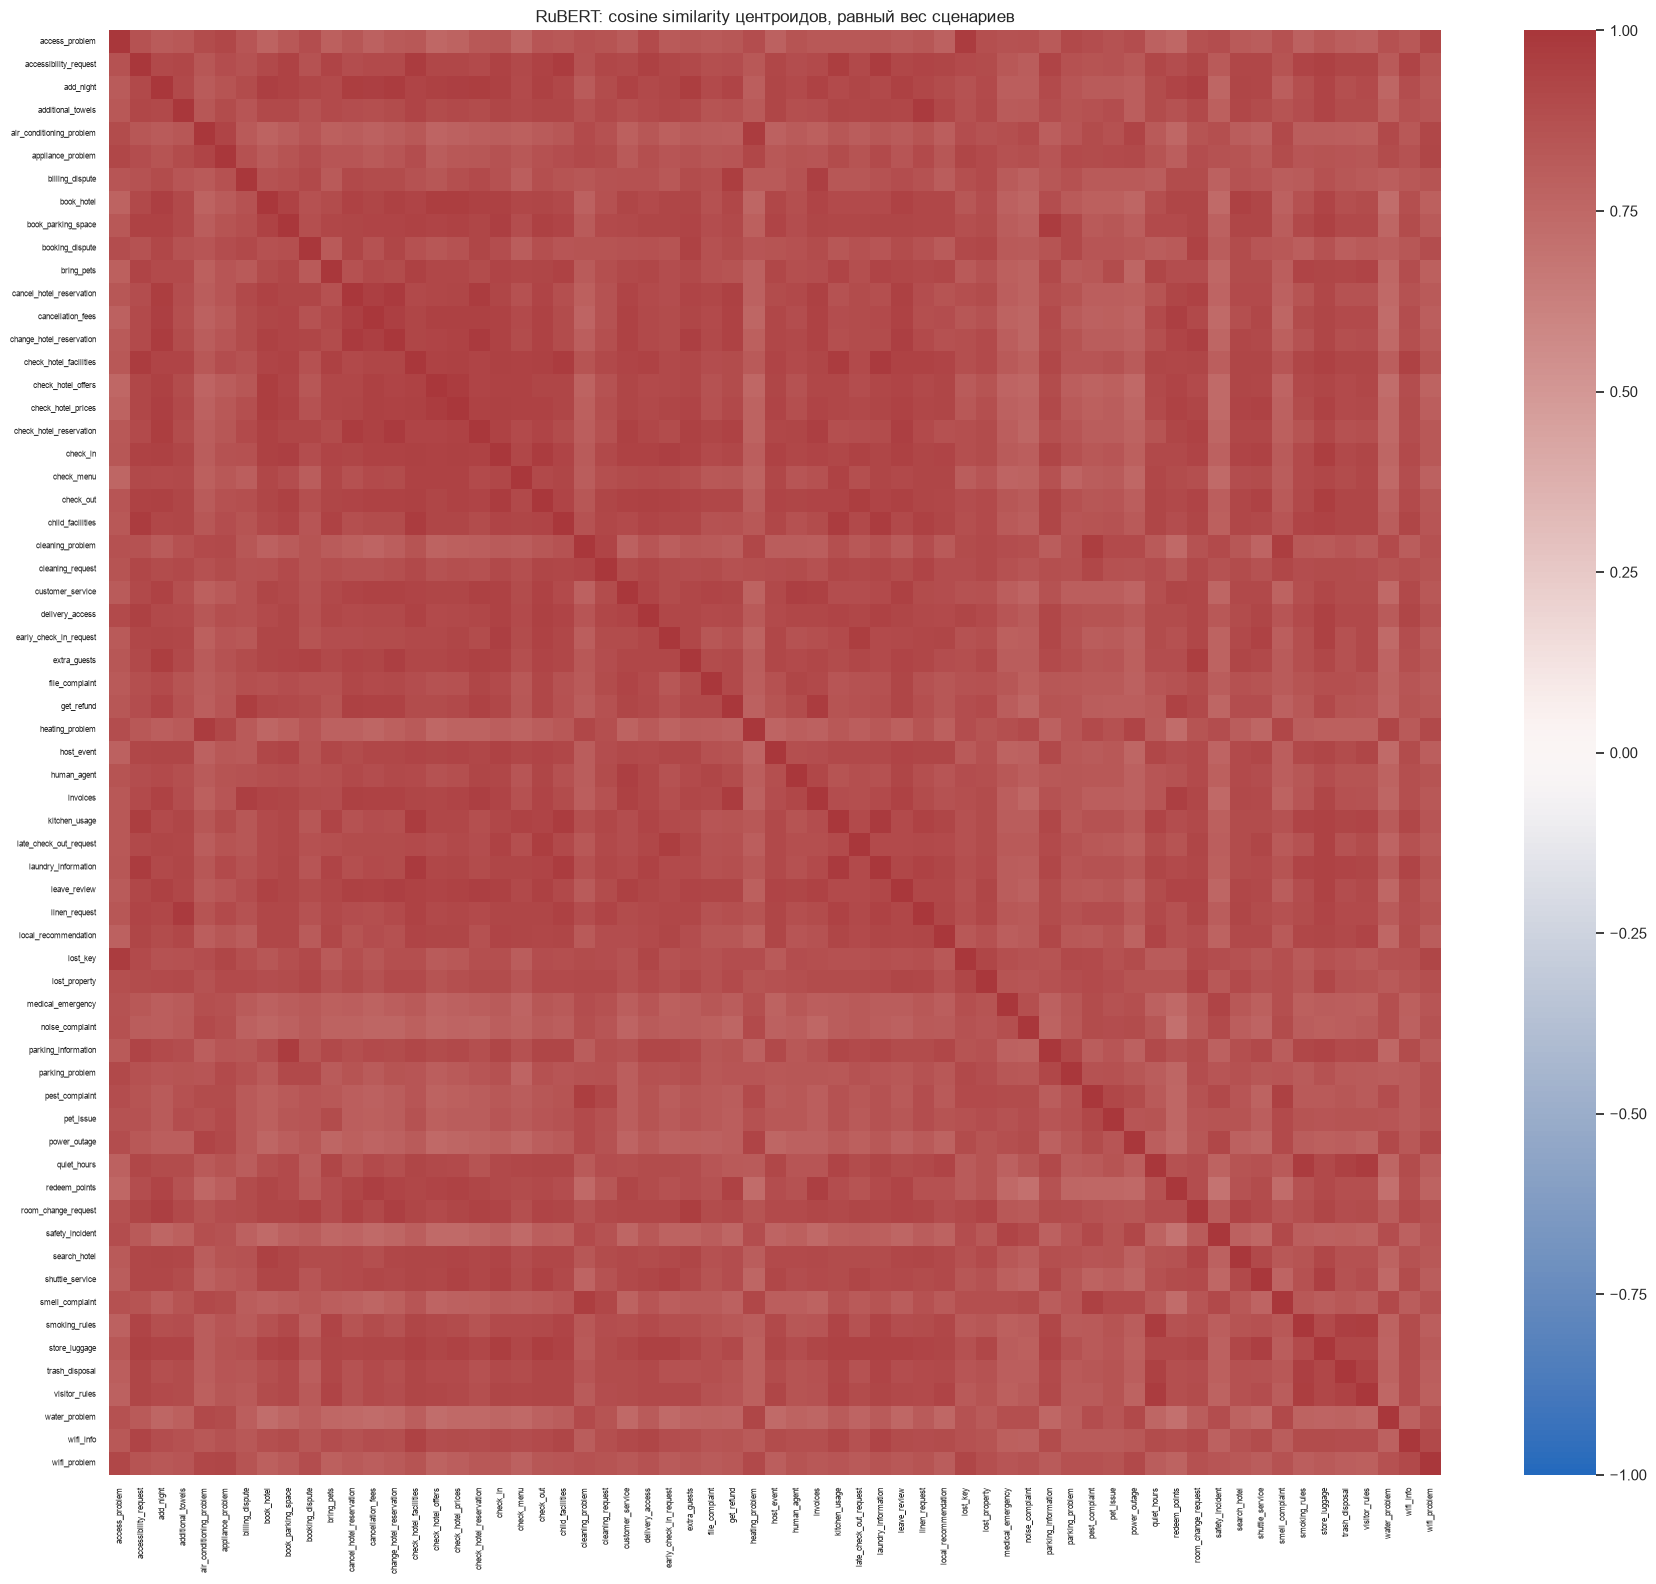

SBERT-ru — наиболее близкие намерения


,intent_a,intent_b,similarity
0,cancel_hotel_reservation,change_hotel_reservation,0.973173
1,access_problem,lost_key,0.972870
2,air_conditioning_problem,heating_problem,0.966374
3,add_night,change_hotel_reservation,0.962970
4,get_refund,invoices,0.959544
5,early_check_in_request,late_check_out_request,0.959159
6,cleaning_problem,smell_complaint,0.957753
7,additional_towels,linen_request,0.953512
8,check_hotel_offers,check_hotel_prices,0.952487
9,check_out,late_check_out_request,0.952044


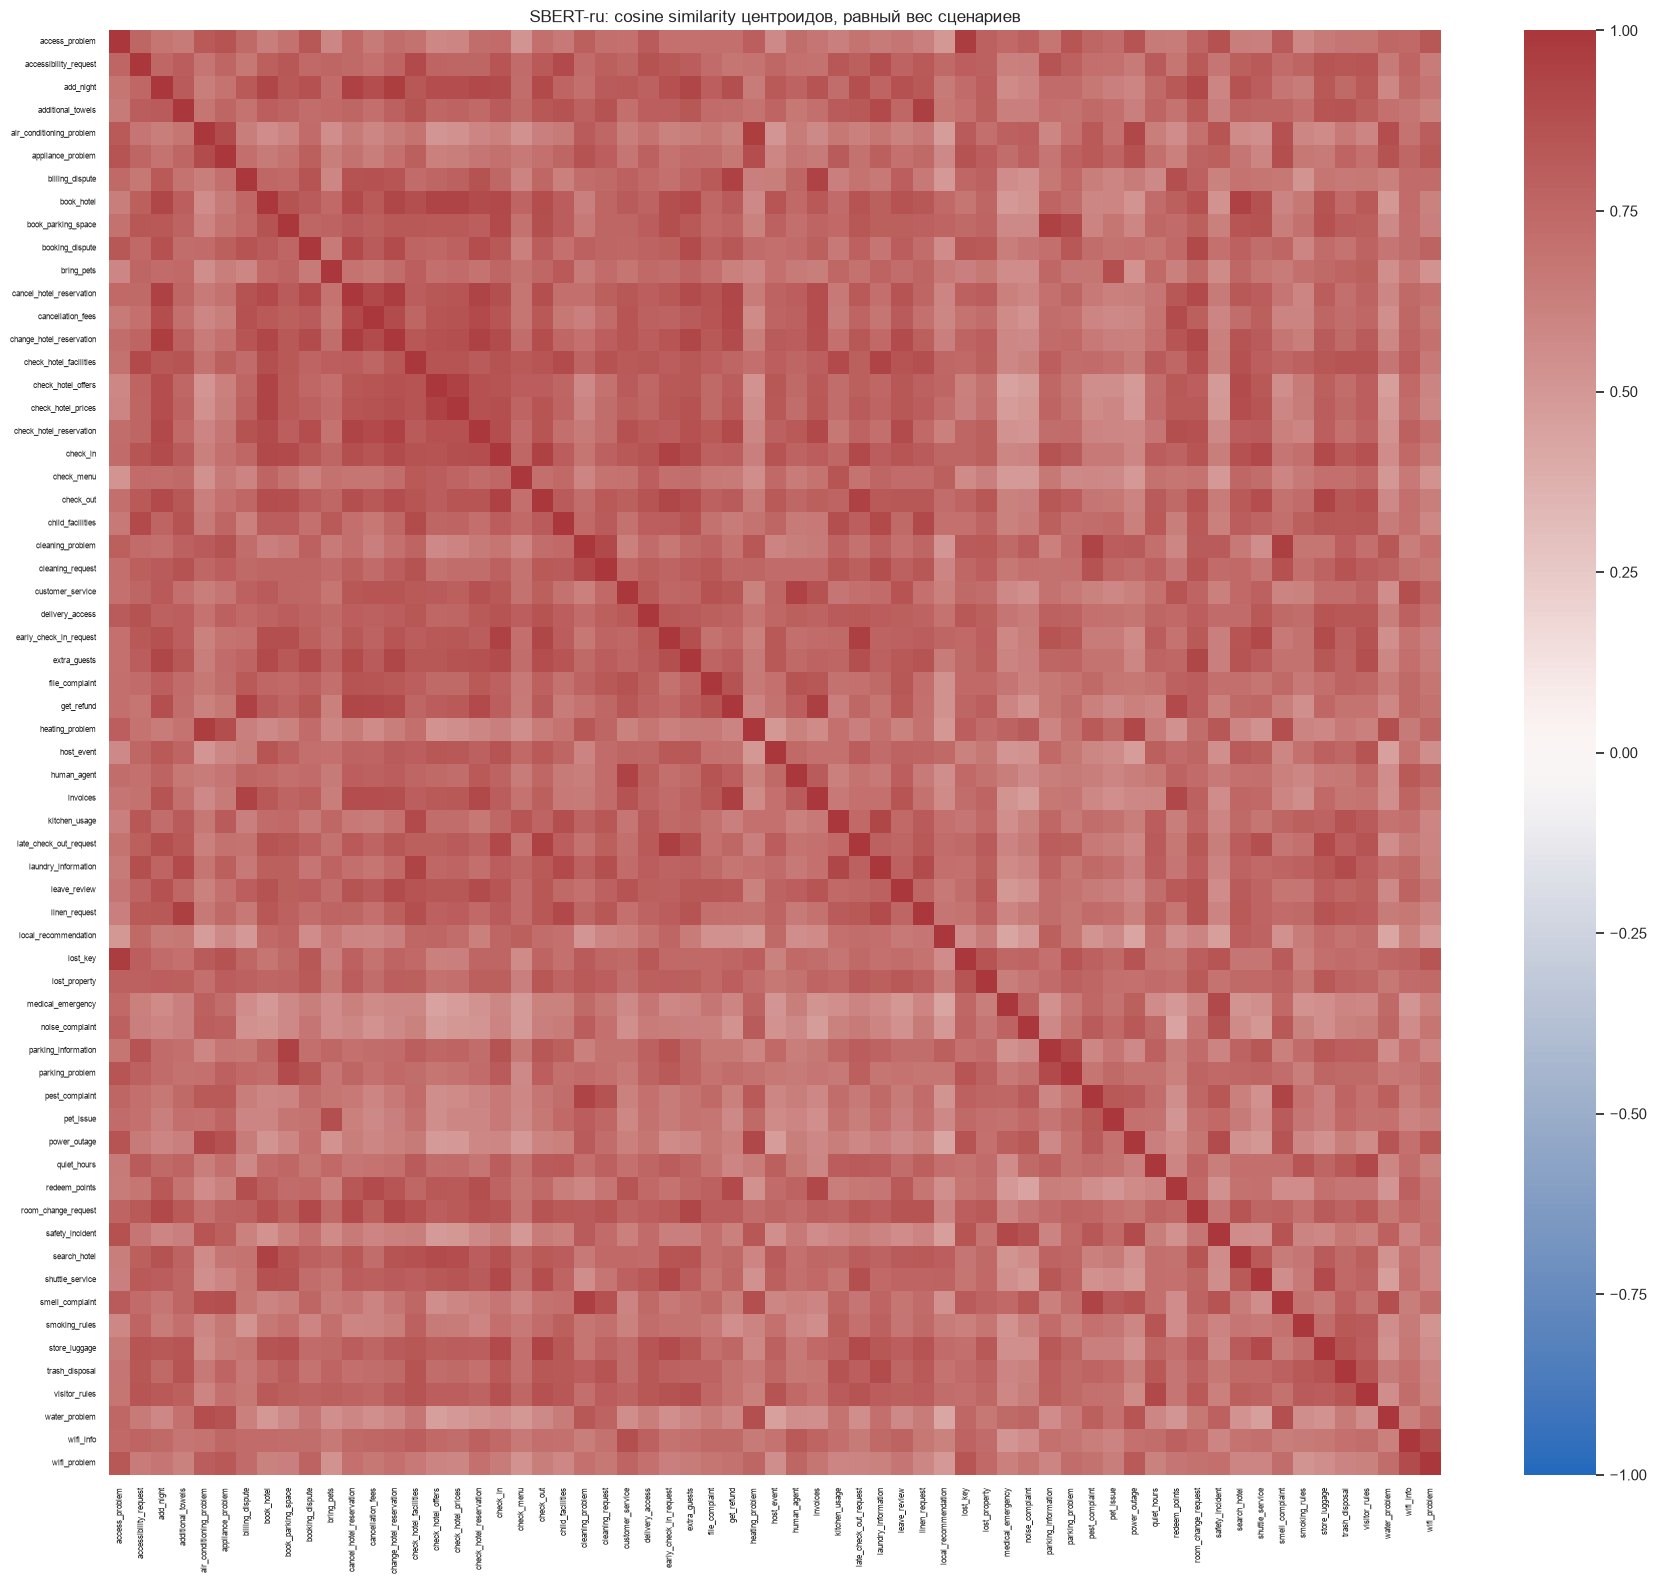

In [58]:
embedding_centroid_results = {}
for embedding_name, embedding_array in embedding_vectors.items():
    embedding_intent_names, embedding_centers, embedding_class_similarity = intent_centroids(embedding_array, embedding_rows)
    embedding_centroid_results[embedding_name] = embedding_class_similarity
    embedding_pairs_table = closest_intents(embedding_intent_names, embedding_class_similarity, limit=20)
    print(embedding_name, '— наиболее близкие намерения')
    display(embedding_pairs_table)
    embedding_fig, embedding_ax = plt.subplots(figsize=(18, 16))
    sns.heatmap(pd.DataFrame(embedding_class_similarity, index=embedding_intent_names, columns=embedding_intent_names),
                vmin=-1, vmax=1, cmap='vlag', ax=embedding_ax)
    embedding_ax.set_title(f'{embedding_name}: cosine similarity центроидов, равный вес сценариев')
    embedding_ax.tick_params(axis='both', labelsize=6)
    embedding_fig.tight_layout()
    embedding_fig.savefig(embedding_results_dir / f'{embedding_name}_intent_centroids.png', dpi=150, bbox_inches='tight')
    plt.show()
    embedding_pairs_table.to_csv(embedding_results_dir / f'{embedding_name}_closest_intents.csv',
                                 index=False, encoding='utf-8-sig')


### 5.6. Пары для ручной проверки

Точно просматриваем соседей для **всех** уникальных текстов блоками, но сохраняем только top-20
для каждого запроса. После удаления симметричных пар этого достаточно для глобального top-20.
В первом проходе исключаем свой сценарий и text_key; во втором также требуем разные intent.
Первые 20 пар могут включать равные similarity — порядок внутри таких равенств не имеет
содержательного смысла. Не задаём универсального порога «семантического дубля» и не удаляем
пары автоматически. Близкая пара с разными метками требует просмотра текста и правил разметки.

Этот полный проход по парам может занимать больше времени, чем предыдущие диагностические
таблицы, особенно на CPU; он не строит и не сохраняет полную матрицу расстояний.


In [59]:
embedding_manual_pair_tables = {}
embedding_all_indices = np.arange(len(embedding_rows))
for embedding_name, embedding_array in embedding_vectors.items():
    embedding_score = make_embedding_score_blocks(embedding_array, embedding_device)
    try:
        for embedding_different_labels in [False, True]:
            embedding_pair_indices, embedding_pair_scores = nearest_neighbors(
                embedding_array, embedding_rows, embedding_all_indices, k=20,
                exclude_scenario=True, different_intent=embedding_different_labels,
                block_size=128, score_block=embedding_score,
            )
            embedding_pair_table = closest_pairs(
                embedding_rows, embedding_all_indices, embedding_pair_indices, embedding_pair_scores, limit=20
            )
            embedding_manual_pair_tables[(embedding_name, embedding_different_labels)] = embedding_pair_table
            print(embedding_name, '— разные intent' if embedding_different_labels else '— разные сценарии')
            with pd.option_context('display.max_colwidth', 180):
                display(embedding_pair_table)
            embedding_pair_table.to_csv(
                embedding_results_dir / f'{embedding_name}_pairs_different_intent_{embedding_different_labels}.csv',
                index=False, encoding='utf-8-sig',
            )
    finally:
        del embedding_score
        gc.collect()
        clear_embedding_device(embedding_device)


RuBERT — разные сценарии


,request_a,text_a,intent_a,group_a,request_b,text_b,intent_b,group_b,similarity
0,bitext_04163,"Да что же это такое, как связаться со службой поддержки? Подскажите, где это можно сделать.",customer_service,bitext__customer_service__38,bitext_05223,"Да что же это такое, как позвонить представителю поддержки? Подскажите, где это можно сделать.",human_agent,bitext__human_agent__98,0.977308
1,bitext_02632,"Блин, хочу уточнить условия раннего заеда. Подскажите, где это можно сделать.",check_in,bitext__check_in__59,bitext_03352,"Блин, хочу уточнить условия позднего выеда. Подскажите, где это можно сделать.",check_out,bitext__check_out__45,0.976483
2,bitext_00936,"Да что же это такое, мне нужно проверить счета за проживание. Можете подсказать?",invoices,bitext__invoices__52,bitext_23025,"Да что же это такое, мне нужно вернуть оплату за проживание. Можете подсказать?",get_refund,bitext__get_refund__75,0.972323
3,bitext_04173,"Да что же это такое, как связаться со службой поддержки? Нужна ваша помощь.",customer_service,bitext__customer_service__38,bitext_05631,"Да что же это такое, как позвонить представителю поддержки? Нужна ваша помощь.",human_agent,bitext__human_agent__98,0.972076
4,bitext_00874,"Да что же это такое, мне нужно проверить счета за проживание. Как это оформить?",invoices,bitext__invoices__52,bitext_23399,"Да что же это такое, мне нужно вернуть оплату за проживание. Как это оформить?",get_refund,bitext__get_refund__75,0.972009
5,bitext_04216,"Как связаться со службой поддержки? Подскажите, где это можно сделать.",customer_service,bitext__customer_service__38,bitext_05229,"Как позвонить представителю поддержки? Подскажите, где это можно сделать.",human_agent,bitext__human_agent__98,0.971360
6,bitext_17183,"Блин, можно оставить багаж на хранение? Мне нужно оставить вещи до заселения. Можете подсказать?",store_luggage,bitext__store_luggage__28,bitext_17712,"Блин, можно оставить чемодан после выезда? Мне нужно оставить вещи до заселения. Можете подсказать?",store_luggage,bitext__store_luggage__31,0.970932
7,bitext_04973,"Да что же это такое, как связаться со службой поддержки? Поможете разобраться?",customer_service,bitext__customer_service__38,bitext_05069,"Да что же это такое, как позвонить представителю поддержки? Поможете разобраться?",human_agent,bitext__human_agent__98,0.970899
8,bitext_04931,"Да что же это такое, как связаться со службой поддержки? Подсккажите, где это можно сделать.",customer_service,bitext__customer_service__38,bitext_05223,"Да что же это такое, как позвонить представителю поддержки? Подскажите, где это можно сделать.",human_agent,bitext__human_agent__98,0.970851
9,bitext_17143,"Чёрт возьми, можно оставить багаж на хранение? Мне нужно оставить вещи до заселения. Поможете разобраться?",store_luggage,bitext__store_luggage__28,bitext_17191,"Чёрт возьми, можно оставить чемодан после выезда? Мне нужно оставить вещи до заселения. Поможете разобраться?",store_luggage,bitext__store_luggage__31,0.970842


RuBERT — разные intent


,request_a,text_a,intent_a,group_a,request_b,text_b,intent_b,group_b,similarity
0,bitext_04163,"Да что же это такое, как связаться со службой поддержки? Подскажите, где это можно сделать.",customer_service,bitext__customer_service__38,bitext_05223,"Да что же это такое, как позвонить представителю поддержки? Подскажите, где это можно сделать.",human_agent,bitext__human_agent__98,0.977308
1,bitext_02632,"Блин, хочу уточнить условия раннего заеда. Подскажите, где это можно сделать.",check_in,bitext__check_in__59,bitext_03352,"Блин, хочу уточнить условия позднего выеда. Подскажите, где это можно сделать.",check_out,bitext__check_out__45,0.976483
2,bitext_00936,"Да что же это такое, мне нужно проверить счета за проживание. Можете подсказать?",invoices,bitext__invoices__52,bitext_23025,"Да что же это такое, мне нужно вернуть оплату за проживание. Можете подсказать?",get_refund,bitext__get_refund__75,0.972323
3,bitext_04173,"Да что же это такое, как связаться со службой поддержки? Нужна ваша помощь.",customer_service,bitext__customer_service__38,bitext_05631,"Да что же это такое, как позвонить представителю поддержки? Нужна ваша помощь.",human_agent,bitext__human_agent__98,0.972076
4,bitext_00874,"Да что же это такое, мне нужно проверить счета за проживание. Как это оформить?",invoices,bitext__invoices__52,bitext_23399,"Да что же это такое, мне нужно вернуть оплату за проживание. Как это оформить?",get_refund,bitext__get_refund__75,0.972009
5,bitext_04216,"Как связаться со службой поддержки? Подскажите, где это можно сделать.",customer_service,bitext__customer_service__38,bitext_05229,"Как позвонить представителю поддержки? Подскажите, где это можно сделать.",human_agent,bitext__human_agent__98,0.971360
6,bitext_04973,"Да что же это такое, как связаться со службой поддержки? Поможете разобраться?",customer_service,bitext__customer_service__38,bitext_05069,"Да что же это такое, как позвонить представителю поддержки? Поможете разобраться?",human_agent,bitext__human_agent__98,0.970899
7,bitext_04931,"Да что же это такое, как связаться со службой поддержки? Подсккажите, где это можно сделать.",customer_service,bitext__customer_service__38,bitext_05223,"Да что же это такое, как позвонить представителю поддержки? Подскажите, где это можно сделать.",human_agent,bitext__human_agent__98,0.970851
8,bitext_00997,"Да что же это такое, мне нужно проверить счета за проживание. Где мне найти нужный раздел?",invoices,bitext__invoices__52,bitext_23379,"Да что же это такое, мне нужно вернуть оплату за проживание. Где мне найти нужный раздел?",get_refund,bitext__get_refund__75,0.970571
9,bitext_03494,"Да что же это такое, как продлть время выезда? Подскажите, где это можно сделать.",check_out,bitext__check_out__66,bitext_19074,"Да что же это такое, как продлть срок проживания? Подскажите, где это можно сделать.",add_night,bitext__add_night__3,0.970107


SBERT-ru — разные сценарии


,request_a,text_a,intent_a,group_a,request_b,text_b,intent_b,group_b,similarity
0,bitext_00928,Мне нужно проерить счета за проживание. Нужна ваша помощь.,invoices,bitext__invoices__52,bitext_23204,Мне нужно вренуть оплату за проживание. Нужна ваша помощь.,get_refund,bitext__get_refund__75,0.981927
1,bitext_00714,"Чёрт возьми, мне нужно порверить счета за проживание. Нужна ваша помощь.",invoices,bitext__invoices__52,bitext_23448,"Чёрт возьми, мне нужно вернуть оплату за проживание. Нужна ваша помощь.",get_refund,bitext__get_refund__75,0.980828
2,bitext_00928,Мне нужно проерить счета за проживание. Нужна ваша помощь.,invoices,bitext__invoices__52,bitext_23536,Мне нужно врнуть оплату за проживание. Нужна ваша помощь.,get_refund,bitext__get_refund__75,0.979732
3,ru_native_00861,"Пробовали открыть дверь несколько раз. Внешняя дверь закрыта, код перестал срабатывать. Мы приехали с чемоданами.",access_problem,ru_v2__access_problem__seed09,ru_native_09905,"Пробовали открыть дверь несколько раз. Код на двери не принимается, мы снаружи. Мы приехали с чемоданами.",access_problem,ru_v2__access_problem__seed00,0.978816
4,bitext_00928,Мне нужно проерить счета за проживание. Нужна ваша помощь.,invoices,bitext__invoices__52,bitext_23153,Мне нужно вернуть оплаату за проживание. Нужна ваша помощь.,get_refund,bitext__get_refund__75,0.971125
5,bitext_02632,"Блин, хочу уточнить условия раннего заеда. Подскажите, где это можно сделать.",check_in,bitext__check_in__59,bitext_03352,"Блин, хочу уточнить условия позднего выеда. Подскажите, где это можно сделать.",check_out,bitext__check_out__45,0.970355
6,ru_native_03063,"Мне важно сохранить документы в электронном виде. В счёте есть доплата, о которой не предупреждали. Можно подсказать, что делать дальше?",billing_dispute,ru_v2__billing_dispute__seed07,ru_native_07652,"Мне важно сохранить документы в электронном виде. Сумма в подтверждении отличается от списанной. Можно подсказать, что делать дальше?",billing_dispute,ru_v2__billing_dispute__seed04,0.969810
7,bitext_00928,Мне нужно проерить счета за проживание. Нужна ваша помощь.,invoices,bitext__invoices__52,bitext_23243,Мне нужно вернуть оплату за проживание. Нужна ваша помощь.,get_refund,bitext__get_refund__75,0.969745
8,bitext_00928,Мне нужно проерить счета за проживание. Нужна ваша помощь.,invoices,bitext__invoices__52,bitext_23725,Мне нужжно вернуть оплату за проживание. Нужна ваша помощь.,get_refund,bitext__get_refund__75,0.969635
9,bitext_00928,Мне нужно проерить счета за проживание. Нужна ваша помощь.,invoices,bitext__invoices__52,bitext_23406,Мне нужно вернуть оплату за проживание. Нужа ваша помощь.,get_refund,bitext__get_refund__75,0.968207


SBERT-ru — разные intent


,request_a,text_a,intent_a,group_a,request_b,text_b,intent_b,group_b,similarity
0,bitext_00928,Мне нужно проерить счета за проживание. Нужна ваша помощь.,invoices,bitext__invoices__52,bitext_23204,Мне нужно вренуть оплату за проживание. Нужна ваша помощь.,get_refund,bitext__get_refund__75,0.981927
1,bitext_00714,"Чёрт возьми, мне нужно порверить счета за проживание. Нужна ваша помощь.",invoices,bitext__invoices__52,bitext_23448,"Чёрт возьми, мне нужно вернуть оплату за проживание. Нужна ваша помощь.",get_refund,bitext__get_refund__75,0.980828
2,bitext_00928,Мне нужно проерить счета за проживание. Нужна ваша помощь.,invoices,bitext__invoices__52,bitext_23536,Мне нужно врнуть оплату за проживание. Нужна ваша помощь.,get_refund,bitext__get_refund__75,0.979732
3,bitext_00928,Мне нужно проерить счета за проживание. Нужна ваша помощь.,invoices,bitext__invoices__52,bitext_23153,Мне нужно вернуть оплаату за проживание. Нужна ваша помощь.,get_refund,bitext__get_refund__75,0.971125
4,bitext_02632,"Блин, хочу уточнить условия раннего заеда. Подскажите, где это можно сделать.",check_in,bitext__check_in__59,bitext_03352,"Блин, хочу уточнить условия позднего выеда. Подскажите, где это можно сделать.",check_out,bitext__check_out__45,0.970355
5,bitext_00928,Мне нужно проерить счета за проживание. Нужна ваша помощь.,invoices,bitext__invoices__52,bitext_23243,Мне нужно вернуть оплату за проживание. Нужна ваша помощь.,get_refund,bitext__get_refund__75,0.969745
6,bitext_00928,Мне нужно проерить счета за проживание. Нужна ваша помощь.,invoices,bitext__invoices__52,bitext_23725,Мне нужжно вернуть оплату за проживание. Нужна ваша помощь.,get_refund,bitext__get_refund__75,0.969635
7,bitext_00928,Мне нужно проерить счета за проживание. Нужна ваша помощь.,invoices,bitext__invoices__52,bitext_23406,Мне нужно вернуть оплату за проживание. Нужа ваша помощь.,get_refund,bitext__get_refund__75,0.968207
8,bitext_09373,"Да что же это такое, помогите подобрать и забронровать жильё. Нужна ваша помощь.",book_hotel,bitext__book_hotel__27,bitext_16166,"Да что же это такое, помогите выбрать жильё в городе. Нужна ваша помощь.",search_hotel,bitext__search_hotel__93,0.966911
9,bitext_00275,Мне нужно провериьт счета за проживание. Нужна ваша помощь.,invoices,bitext__invoices__52,bitext_23536,Мне нужно врнуть оплату за проживание. Нужна ваша помощь.,get_refund,bitext__get_refund__75,0.966776


### 5.7. Сравнение моделей

Silhouette рассчитывается с cosine distance в исходном пространстве эмбеддингов на одной
фиксированной выборке, а не на PCA/t-SNE. Это описательный показатель согласованности
геометрии с имеющейся разметкой. Он не доказывает, что модель лучше понимает реальные обращения.
Наличие нескольких текстов одной сценарной группы в выборке тоже влияет на показатель.

Сопоставляем его с соседями без своего сценария и ручными примерами. Время из кеша относится
к исходному устройству, указанному в технической таблице. Значения разных устройств напрямую не сравнивать.


In [60]:
embedding_comparison = embedding_technical.copy()
embedding_sample_labels = embedding_rows.iloc[embedding_visual_indices]['intent'].to_numpy()
for embedding_name, embedding_array in embedding_vectors.items():
    embedding_n_labels = len(np.unique(embedding_sample_labels))
    if 2 <= embedding_n_labels < len(embedding_visual_indices):
        embedding_silhouette = silhouette_score(
            embedding_array[embedding_visual_indices], embedding_sample_labels, metric='cosine'
        )
    else:
        embedding_silhouette = np.nan
        print('Silhouette не определён: нужны минимум два класса и больше объектов, чем классов.')
    embedding_comparison.loc[embedding_name, 'Silhouette intent (cosine)'] = embedding_silhouette
    for embedding_mode, embedding_label in [('обычные соседи', 'Обычные'), ('без своего сценария', 'Без сценария')]:
        embedding_metric = embedding_neighbor_table.loc[
            embedding_neighbor_table['Модель'].eq(embedding_name) & embedding_neighbor_table['Режим'].eq(embedding_mode)
        ].iloc[0]
        embedding_comparison.loc[embedding_name, f'{embedding_label}: совпадение intent@5'] = embedding_metric['micro_agreement']
        embedding_comparison.loc[embedding_name, f'{embedding_label}: macro по intent'] = embedding_metric['macro_intent_agreement']
    embedding_comparison.loc[embedding_name, 'Падение при исключении сценария'] = (
        embedding_comparison.loc[embedding_name, 'Обычные: совпадение intent@5']
        - embedding_comparison.loc[embedding_name, 'Без сценария: совпадение intent@5']
    )
display(embedding_comparison)
embedding_comparison.to_csv(embedding_results_dir / 'model_comparison.csv', encoding='utf-8-sig')
embedding_neighbor_table.to_csv(embedding_results_dir / 'neighbor_agreement.csv', index=False, encoding='utf-8-sig')
embedding_mapping.to_csv(embedding_results_dir / 'request_embedding_mapping.csv', index=False, encoding='utf-8-sig')
embedding_run_manifest = {
    'seed': EMBEDDING_SEED, 'unique_request_ids': embedding_rows['request_id'].tolist(),
    'visual_request_ids': embedding_rows.iloc[embedding_visual_indices]['request_id'].tolist(),
    'query_request_ids': embedding_rows.iloc[embedding_queries]['request_id'].tolist(),
    'models': {name: {key: value for key, value in meta.items() if key not in ['ids', 'token_lengths']}
               for name, meta in embedding_metadata.items()},
}
(embedding_results_dir / 'analysis_manifest.json').write_text(
    json.dumps(embedding_run_manifest, ensure_ascii=False, indent=2)
)
print('Результаты сохранены:', embedding_results_dir)


,Размерность,Уникальных текстов,"Кодирование, с","Усечение уникальных, доля","Усечение исходных строк, доля",Устройство исходного расчёта,Batch size итоговый,Из кеша,Ревизия,Silhouette intent (cosine),Обычные: совпадение intent@5,Обычные: macro по intent,Без сценария: совпадение intent@5,Без сценария: macro по intent,Падение при исключении сценария
Модель,,,,,,,,,,,,,,,
RuBERT,768,28800,82.706212,0.0,0.0,Apple Silicon / MPS (arm64),16,False,4036cab694767a299f2b9e6492909664d9414229,-0.011685,0.6678,0.668373,0.379,0.380265,0.2888
SBERT-ru,1024,28800,253.748898,0.0,0.0,Apple Silicon / MPS (arm64),8,False,89deeaa197d9d146e5763ac1f5fe32bf66817126,0.031332,0.8200,0.820675,0.512,0.513280,0.3080


Результаты сохранены: /Users/leonidbeleckij/Documents/HSE/Year project/rental-ai-assistant/artifacts/text_embeddings/analysis


### 5.8. Итоговые выводы по результатам локального расчёта

Рассмотрены 35 000 русскоязычных обращений, 28 800 уникальных очищенных текстов и 902 сценарные группы.
Обе модели рассчитаны на Apple Silicon / MPS, без усечения текстов при max_length=128 и без уменьшения
batch size из-за нехватки памяти. Для проекций и silhouette использовались одинаковые 2705 текстов,
для анализа соседей — одинаковые 1000 запросов. Каждый запрос имел пять доступных соседей в обоих режимах.

| Модель | Размерность | Кодирование, с | Совпадение intent@5: обычные соседи | Без своего сценария и одинакового text_key | Silhouette по intent |
|---|---|---|---|---|---|
| RuBERT | 768 | 82,7 | 66,78% | 37,90% | -0,0117 |
| SBERT-ru | 1024 | 253,7 | 82,00% | 51,20% | 0,0313 |

Доли совпадений описывают согласованность соседей с имеющимися метками, а не accuracy обученного
классификатора. Средние по намерениям близки к общим долям: без собственного сценария macro составляет
38,03% для RuBERT и 51,33% для SBERT-ru. Следовательно, преимущество SBERT в этом эксперименте
наблюдается и при усреднении по намерениям, а не только по всем соседям вместе.

| Вопрос | Наблюдение | Доказательство | Ограничение | Применение в проекте |
|---|---|---|---|---|
| Какие намерения близки и требуют проверки границ? | У SBERT-ru близки отмена и изменение бронирования (cosine центроидов 0,9732), проблема доступа и потеря ключа (0,9729), кондиционер и отопление (0,9664). Счета и возврат оплаты также близки (0,9595). Это тематическая близость, хотя требуемые действия могут различаться. | §5.5: матрицы и таблицы центроидов; §5.6: реальные пары `check_in`/`check_out`, `invoices`/`get_refund`. | Центроиды усредняют неоднородные тексты. Близость не является ошибкой классификации: классификатор не обучался. Абсолютные значения cosine не сопоставляются между моделями как вероятности. | Уточнить определения соседних intent и собрать контрастные примеры. Проверять различие нужного действия, особенно для отмены, изменения брони и возврата денег; не объединять классы автоматически. |
| Насколько влияют сценарные шаблоны? | После исключения собственного сценария и одинакового `text_key` согласованность top-5 у RuBERT снижается с 66,78% до 37,90% (−28,88 п. п.), у SBERT-ru — с 82,00% до 51,20% (−30,80 п. п.). Высокий результат обычного поиска существенно поддерживается близкими вариантами сценариев. | §5.4: таблица двух режимов; §5.7: сводное сравнение. Те же 1000 запросов и пять соседей на запрос в каждом режиме. | Одновременно исключаются сценарий и одинаковый нормализованный ключ, поэтому их отдельные эффекты не измерены. `scenario_group_id` задан при создании корпуса и может не объединять все смысловые перефразирования. Это диагностический анализ, а не оценка на независимом тесте реальных гостей. | Разделять будущие обучающие выборки по сценарным группам, учитывать точные повторы и дополнительно проверять смысловую близость между группами. Не оценивать обобщение только по обычным соседям. |
| Найдены ли кандидаты в смысловые повторы? | Да: SBERT-ru сближает обращения о неработающем коде двери из разных групп `access_problem` (0,9788), а RuBERT — варианты запроса о хранении багажа из разных групп `store_luggage` (например, 0,9709). Одновременно SBERT даёт 0,9819 паре о проверке счетов и возврате оплаты: высокая близость возможна при разных действиях. | §5.6: таблицы наиболее близких пар, включая отдельный проход по разным intent. В 20 наиболее близких разносценарных парах одинаковый intent у 7 пар RuBERT и 6 пар SBERT-ru. | Это целенаправленно выбранные самые близкие пары, а не репрезентативная оценка доли дублей. Совпадение метки и высокая similarity сами по себе не доказывают эквивалентность; в примерах видны общие вводные фразы и опечатки. | Использовать пары как список кандидатов для ручного аудита, уточнения меток и группировки перефразирований. Проверять условия и действие перед удалением или объединением записей; не вводить универсальный порог дубля. |
| Какая модель полезнее на текущем корпусе? | SBERT-ru показывает более высокую согласованность соседей: после фильтрации 51,20% против 37,90% у RuBERT (+13,30 п. п.). Silhouette также выше: 0,0313 против −0,0117. При этом оба значения близки к нулю, поэтому чёткое разделение всех 63 намерений не подтверждено. SBERT кодировал корпус за 253,7 с против 82,7 с у RuBERT. | §5.7: сводная таблица; §5.2: один тип устройства MPS, размерности 1024 и 768, итоговые batch size 8 и 16. | SBERT в этом запуске примерно в 3,07 раза медленнее; размеры и batch size моделей различаются. Метки синтетические и не прошли экспертную проверку. Независимого теста релевантности и RAG-качества нет. | Выбрать SBERT-ru основным кандидатом для дальнейших экспериментов с семантическим поиском, сохранив RuBERT как более быстрый ориентир. Перед продуктовым выбором проверить на вопросах реальных гостей и документах конкретного объекта. |
| Что видно по источникам данных? | На проекциях присутствуют локальные области с преобладанием одного источника; это особенно заметно на t-SNE SBERT-ru. При этом первые две компоненты PCA объясняют лишь 16,3% дисперсии RuBERT и 16,7% SBERT-ru. В исходной таблице bitext представлен 25 намерениями, team_generated_ru_v2 — всеми 63; общих намерений 25. | §5.3: одинаковая выборка 2705 текстов с окраской по `source_display`; дополнительная проверка состава `intent` по `source_dataset` в исходном CSV. | По картинке нельзя отделить влияние стиля генерации от различий тем и частот классов. t-SNE искажает глобальные расстояния, а небольшая доля дисперсии PCA ограничивает интерпретацию двумерного вида. | Проверить источники отдельно на общих 25 intent с сопоставимыми объёмами и добавить независимые реальные обращения. Не выдавать визуальное разделение источников за доказанное различие качества данных или моделей. |

**Практическое следствие для данных:** корпус содержит много близких шаблонных вариантов; кроме
сценарного разделения, необходимы проверка границ intent и ручной разбор близких пар. Сходство
формулировок может скрывать разные действия: ранний заезд и поздний выезд, проверка счёта и возврат.

**Границы выводов:** классификатор не обучался; качество эскалации, RAG и ответов гостям здесь
не измерялось. Все строки имеют `is_synthetic=1` и `annotation_status=requires_manual_review`.
Предпочтение SBERT относится к описанному корпусу и диагностическим метрикам; оно не доказывает
превосходство на реальных обращениях. 